# Nigeria Inflation Forecast

Nigerian households and small businesses set prices, salaries and savings without knowing where inflation is heading.
Headline inflation peaked above 30% in 2024, the CPI was rebased in January 2025, and inflation has since fallen to about 14.6% (September 2026).
**Will that decline continue, level off, or reverse?**

In this notebook we pull Nigeria's monthly inflation, crude oil prices and the naira/dollar exchange rate from the Central Bank of Nigeria (CBN),
explore them, compare forecasting models against a naive baseline, and forecast the next 6–12 months with an uncertainty range.

## 1. Setup

We load the libraries we need:

- `pandas`: tables (DataFrames) and time-series tools
- `requests`: downloads data from a web address (URL)
- `matplotlib.pyplot`: draws charts
- `Path`: builds file paths that work on Windows, Mac and Linux

We also fix one colour per series, so headline is always blue, food always orange and core always green in every chart.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

# Chart colours used throughout the notebook (one fixed colour per series)
HEADLINE_COLOUR = "#2a78d6"  # blue
FOOD_COLOUR = "#eb6834"      # orange
CORE_COLOUR = "#1baf7a"      # green
FX_COLOUR = "#6250d6"        # violet, for the naira/dollar rate
CRUDE_COLOUR = "#eda100"     # yellow, for crude oil
REBASE_COLOUR = "#52514e"    # dark grey, for the January 2025 rebasing marker

## 2. Data pull

**Question:** Can we pull Nigeria's monthly inflation, crude oil price and naira/dollar rate straight from the CBN and combine them into one monthly table?

The data pages on cbn.gov.ng load their numbers from hidden **JSON feeds**. JSON is a text format for data: here, each feed is a long list of
records, and each record (one month or one day) becomes a row in our table.

These feeds are **undocumented**, so the CBN could change or remove them without warning. That's why we always save a CSV copy after a
successful pull, and fall back to that copy if the download fails.

In [2]:
# The three hidden JSON feeds behind cbn.gov.ng data pages (undocumented, so they may change)
BASE_URL = "https://www.cbn.gov.ng/api/"
INFLATION_ENDPOINT = "GetAllInflationRates"
CRUDE_ENDPOINT = "GetAllDailyCrude"
FX_ENDPOINT = "GetAllExchangeRates"

# Some servers refuse requests that don't look like they come from a web browser,
# so we send the same "User-Agent" label a normal browser would
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/130.0 Safari/537.36"
}

# Where we keep our saved copy of the cleaned monthly table
CSV_PATH = Path("data") / "nigeria_macro.csv"

### 2.1 Download the three feeds

`requests.get()` asks the server for a URL and returns a **response**. Every response has a **status code**: `200` means OK,
`403` means "forbidden" (blocked), `404` means "not found". `raise_for_status()` turns any bad status code into an error, so a
failed download can't slip through silently. `timeout=60` means: give up after 60 seconds instead of waiting forever.

We wrap the downloads in `try` / `except`. If **anything** goes wrong (no internet, the server blocks us, the reply isn't valid JSON),
we print the problem and set `live_data = False`. Later cells then load the saved CSV instead of crashing.

In [3]:
def fetch_json(endpoint):
    # Download one CBN feed and return it as a list of records (dictionaries)
    url = BASE_URL + endpoint
    response = requests.get(url, headers=HEADERS, timeout=60)
    response.raise_for_status()  # stop with an error if the server says no (e.g. 403 or 404)
    records = response.json()
    print(f"{endpoint}: {len(records):,} records")
    return records

In [4]:
try:
    inflation_raw = fetch_json(INFLATION_ENDPOINT)
    crude_raw = fetch_json(CRUDE_ENDPOINT)
    fx_raw = fetch_json(FX_ENDPOINT)
    live_data = True
except (requests.RequestException, ValueError) as error:
    # RequestException = network problem or bad status code; ValueError = the reply wasn't valid JSON
    print("Could not get live data from the CBN API:", error)
    print("We'll load the saved CSV copy instead.")
    live_data = False

GetAllInflationRates: 285 records
GetAllDailyCrude: 3,978 records
GetAllExchangeRates: 62,463 records


Let's look at one raw record from each feed before cleaning anything.

*Cells that start with `if live_data:` only do something when the download worked.*

In [5]:
if live_data:
    print(inflation_raw[0])
    print(crude_raw[0])
    print(fx_raw[0])

{'id': 298, 'tyear': 2026, 'tmonth': 9, 'period': 'September 2026', 'allItemsYearOn': '14.63', 'allItemsAverage': '15.80', 'foodYearOn': '19.59', 'foodAverage': '15.72', 'allItemsLessFrmProdYearOn': '12.78', 'allItemsLessFrmProdAverage': '15.91', 'allItemsLessFrmProdAndEnergyYearOn': '12.95', 'allItemsLessFrmProdAndEnergyAvg': '16.54'}
{'id': 4998, 'postDate': '22/10/2026', 'crudeOilPrice': '123.9700'}
{'id': 65235, 'currency': 'CFA', 'ratedate': '2026-10-23', 'buyingrate': '2.2756', 'centralrate': '2.2856', 'sellingrate': '2.2956'}


**Finding:** All three feeds downloaded (285 monthly inflation records, about 4,000 daily crude prices and about 62,000 daily exchange rates).
Three things to fix while cleaning:
1. **Every number is text.** Notice the quotes in `'allItemsYearOn': '14.63'`. We can't do maths on text, so we convert with `pd.to_numeric`.
2. **Newest first.** Time series should run oldest → newest.
3. **Different date styles.** Inflation has separate year and month numbers, crude uses `dd/mm/yyyy`, and exchange rates use `yyyy-mm-dd`.

### 2.2 Clean the inflation feed

We keep three **year-on-year** rates. "Year-on-year" means: how much higher prices are than in the same month last year.

| Feed column | Our name | Meaning |
|---|---|---|
| `allItemsYearOn` | `Headline` | All goods and services |
| `foodYearOn` | `Food` | Food only |
| `allItemsLessFrmProdAndEnergyYearOn` | `Core` | Everything except farm produce and energy, the less volatile part |

We build a proper date from `tyear` and `tmonth`, using **day 1** of each month. Every series in this project will use
month-start dates, so they line up exactly when we combine them.

In [6]:
def clean_inflation(records):
    # Turn the raw inflation records into a monthly table, oldest month first
    df = pd.DataFrame(records)

    # Build a real date from the year and month columns (day 1 = "month start")
    df["Date"] = pd.to_datetime({"year": df["tyear"], "month": df["tmonth"], "day": 1})

    # Keep only the year-on-year rates we need, with short names
    df = df.rename(columns={
        "allItemsYearOn": "Headline",
        "foodYearOn": "Food",
        "allItemsLessFrmProdAndEnergyYearOn": "Core",
    })
    df = df[["Date", "Headline", "Food", "Core"]]

    # Convert text like "14.63" to numbers; anything that isn't a number becomes NaN (blank),
    # which our checks in section 2.6 will catch
    for column in ["Headline", "Food", "Core"]:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    # The feed is newest-first; time series should run oldest-first
    df = df.set_index("Date").sort_index()
    return df

In [7]:
if live_data:
    inflation = clean_inflation(inflation_raw)
    print(inflation.dtypes)
    display(inflation.tail())

Headline    float64
Food        float64
Core        float64
dtype: object


,Headline,Food,Core
Date,,,
2026-05-01,15.93,16.96,16.82
2026-06-01,15.91,17.52,15.92
2026-07-01,15.43,20.31,14.97
2026-08-01,15.39,19.57,13.29
2026-09-01,14.63,19.59,12.95


**Finding:** The inflation table has 285 months, from January 2003 to September 2026, with no gaps. The three columns are now
`float64` (decimal numbers) instead of text. In September 2026, headline inflation was **14.63%**, food **19.59%** and core **12.95%**.

### 2.3 Clean the crude oil feed

This is the daily price of **Bonny Light**, Nigeria's main export crude, in US dollars per barrel. Two techniques are new here:

- **An explicit date format.** A date like `03/04/2020` could be 3 April or 4 March. We tell pandas the exact format (`%d/%m/%Y`
  = day/month/year) so it can't guess wrong.
- **Resampling.** Inflation is monthly but crude is daily. `resample("MS").mean()` groups all the days in each month and takes the
  average. `"MS"` means "label each group by its **M**onth **S**tart", so January 2020's average gets the date 2020-01-01, the same
  as January 2020's inflation.

In [8]:
def clean_crude(records):
    # Turn daily crude oil prices into monthly average prices (US$ per barrel)
    df = pd.DataFrame(records)

    # Dates look like "22/10/2026" (day/month/year), so give pandas the exact format
    df["Date"] = pd.to_datetime(df["postDate"], format="%d/%m/%Y")
    df["Crude_USD"] = pd.to_numeric(df["crudeOilPrice"], errors="coerce")

    # Average all the days in each month (this also absorbs the few duplicate days in the feed)
    monthly = df.set_index("Date")["Crude_USD"].resample("MS").mean()
    return monthly.round(2)

In [9]:
if live_data:
    crude_monthly = clean_crude(crude_raw)
    print("First month:", crude_monthly.index.min().date(), "| Last month:", crude_monthly.index.max().date())

    # resample() creates a row for every month, so a month with no daily prices shows up as NaN
    empty_months = crude_monthly[crude_monthly.isna()].index.strftime("%Y-%m").tolist()
    print("Months with no crude prices:", empty_months)
    display(crude_monthly["2020-01":"2020-06"])

First month: 2009-10-01 | Last month: 2026-10-01
Months with no crude prices: ['2019-06', '2019-07']


Date
2020-01-01    66.44
2020-02-01    58.46
2020-03-01    33.02
2020-04-01    14.28
2020-05-01    27.62
2020-06-01    40.23
Freq: MS, Name: Crude_USD, dtype: float64

**Finding:** Crude prices start in **October 2009**, so the combined table will have no crude price for 2003 to September 2009.
**June and July 2019 are missing** from the CBN feed entirely. We'll decide how to handle these gaps in Phase 3.
The April 2020 average is very low, with a few days at $7–10 a barrel. That's not an error: it's the COVID-19 oil price
crash, when lockdowns cut global oil demand.

### 2.4 Clean the exchange-rate feed

This feed has daily official rates for **every** currency, and we only want the US dollar. CLAUDE.md warns that the currency names are messy,
so let's **look before we filter**. `repr()` prints each name with quote marks around it, which makes hidden spaces and tabs (`\t`) visible.

In [10]:
if live_data:
    fx = pd.DataFrame(fx_raw)
    # repr() shows hidden characters, e.g. 'US DOLLAR ' with a trailing space
    for name in sorted(fx["currency"].unique()):
        print(repr(name))

'CFA'
'CFA '
'DANISH KRONA'
'DANISH KRONER'
'EURO'
'EURO\t'
'EURO '
'JAPANESE YEN'
'NAIRA'
'POESO'
'POUND STERLING'
'POUNDS STERLING'
'RIYAL'
'RIYAL '
'SDR'
'SDR\t'
'SDR '
'SOUTH AFRICAN RAND'
'SWISS FRANC'
'SWISS FRANC\t'
'UAE DIRHAM'
'US DOLLAR'
'US DOLLAR '
'WAUA'
'WAUA '
'YEN'
'YEN '
'YUAN/RENMINBI'


**Finding:** The names are messy. There's `'US DOLLAR'` *and* `'US DOLLAR '` (trailing space), `'EURO\t'` (a hidden tab),
and spelling variants like `'DANISH KRONA'` / `'DANISH KRONER'` and `'POUND STERLING'` / `'POUNDS STERLING'`.
If we filtered for `"US DOLLAR"` without cleaning, we'd silently lose the rows with a space. `.str.strip()` removes spaces and tabs
from both ends of each name, which is all the US dollar needs.

Each day has three rates: **buying**, **selling**, and **central** (the official midpoint between them). We use the **central rate**,
in naira per US dollar, then average each month just like crude.

In [11]:
def clean_usd_ngn(records):
    # Pick out the US dollar rows and turn daily rates into monthly averages (naira per dollar)
    df = pd.DataFrame(records)

    # Remove hidden spaces/tabs so "US DOLLAR " and "US DOLLAR" count as the same currency
    df["currency"] = df["currency"].str.strip()
    usd = df[df["currency"] == "US DOLLAR"].copy()

    usd["Date"] = pd.to_datetime(usd["ratedate"])  # already in yyyy-mm-dd format
    usd["USD_NGN"] = pd.to_numeric(usd["centralrate"], errors="coerce")

    monthly = usd.set_index("Date")["USD_NGN"].resample("MS").mean()
    return monthly.round(2)

In [12]:
if live_data:
    usd_ngn_monthly = clean_usd_ngn(fx_raw)
    print("First month:", usd_ngn_monthly.index.min().date(), "| Last month:", usd_ngn_monthly.index.max().date())
    print("Months with no rate:", usd_ngn_monthly.isna().sum())
    # Around the June 2023 float of the naira
    display(usd_ngn_monthly["2023-03":"2023-09"])

First month: 2001-12-01 | Last month: 2026-10-01
Months with no rate: 0


Date
2023-03-01    460.43
2023-04-01    460.42
2023-05-01    460.70
2023-06-01    607.75
2023-07-01    769.82
2023-08-01    761.62
2023-09-01    761.33
Freq: MS, Name: USD_NGN, dtype: float64

**Finding:** The US dollar rate runs from December 2001 with no missing months. The June 2023 float is easy to see: about
**₦461** per dollar in May 2023, **₦608** in June and **₦770** in July. This is a jump of roughly two-thirds in two months. Jumps like this
are **policy decisions**, not random noise, and we'll keep that in mind when modelling.

### 2.5 Combine into one monthly table, save it, or fall back to the saved copy

We use the inflation table as the "spine" and **join** the crude and FX columns onto it, matching rows by `Date`.
`join` keeps only the months in the inflation table, so months the other feeds have but inflation doesn't
(e.g. October 2026, which is only partly over) drop out.

If the download worked, we save the result to `data/nigeria_macro.csv`. If it didn't, we load the last saved copy.

In [13]:
if live_data:
    inflation = clean_inflation(inflation_raw)
    crude_monthly = clean_crude(crude_raw)
    usd_ngn_monthly = clean_usd_ngn(fx_raw)

    macro = inflation.join(crude_monthly).join(usd_ngn_monthly)

    CSV_PATH.parent.mkdir(exist_ok=True)  # make sure the data/ folder exists
    macro.to_csv(CSV_PATH)
    print("Live data pulled and saved to", CSV_PATH)
else:
    macro = pd.read_csv(CSV_PATH, index_col="Date", parse_dates=True)
    print("Loaded saved copy from", CSV_PATH)

Live data pulled and saved to data\nigeria_macro.csv


### 2.6 Check the combined table

After every merge we check four things: the **date range**, **missing months**, **duplicate months** and **blank values**.
A merge can silently create any of these problems.

In [14]:
print("Rows, columns:", macro.shape)
print("From", macro.index.min().date(), "to", macro.index.max().date())

# Every month between the first and last date should appear exactly once
all_months = pd.date_range(macro.index.min(), macro.index.max(), freq="MS")
print("Missing months:", len(all_months.difference(macro.index)))
print("Duplicate months:", macro.index.duplicated().sum())

# Count blank (NaN) values in each column
print("\nBlank values per column:")
print(macro.isna().sum())

Rows, columns: (285, 5)
From 2003-01-01 to 2026-09-01
Missing months: 0
Duplicate months: 0

Blank values per column:
Headline      0
Food          0
Core          0
Crude_USD    83
USD_NGN       0
dtype: int64


In [15]:
display(macro.head())
display(macro.tail())

,Headline,Food,Core,Crude_USD,USD_NGN
Date,,,,,
2003-01-01,10.6,7.5,13.6,NaN,126.59
2003-02-01,7.3,3.5,12.1,NaN,127.00
2003-03-01,5.9,0.1,13.9,NaN,126.86
2003-04-01,8.3,3.3,17.6,NaN,126.98
2003-05-01,8.7,3.3,15.5,NaN,127.17


,Headline,Food,Core,Crude_USD,USD_NGN
Date,,,,,
2026-05-01,15.93,16.96,16.82,112.04,1369.49
2026-06-01,15.91,17.52,15.92,87.70,1366.49
2026-07-01,15.43,20.31,14.97,84.81,1372.75
2026-08-01,15.39,19.57,13.29,94.64,1352.47
2026-09-01,14.63,19.59,12.95,117.10,1326.81


**Finding:** We now have one clean monthly table: **285 months** (January 2003 to September 2026) with columns `Headline`, `Food`, `Core`,
`Crude_USD` and `USD_NGN`, saved to `data/nigeria_macro.csv`. There are no missing or duplicate months. The only blanks are in
`Crude_USD`: 81 months before the crude feed starts (January 2003 to September 2009) plus the June and July 2019 gap, so **83** in total.

Still to come in Phase 3 (data quality): add the `Rebased` marker for the January 2025 CPI rebasing, decide what to do with the crude gaps,
and spot-check the CBN numbers against NBS press releases.

## 3. Data quality

**Question:** Can we trust this table enough to build forecasts on it?

A model can't tell a real price shock from a data error, so we check the data *before* modelling:

1. Are the types and value ranges sensible?
2. Are there any copy errors (a month that exactly repeats the one before)?
3. Does the CBN feed agree with the official NBS press releases?
4. How do we fill the gaps?
5. How do we handle the January 2025 CPI rebasing?

### 3.1 Types and value ranges

`dtypes` shows each column's type, and `describe()` gives a quick summary of each column: count, average (`mean`),
spread (`std`), smallest (`min`), largest (`max`) and the quarter points in between.

In [16]:
print(macro.dtypes)
macro.describe().round(2)

Headline     float64
Food         float64
Core         float64
Crude_USD    float64
USD_NGN      float64
dtype: object


,Headline,Food,Core,Crude_USD,USD_NGN
count,285.00,285.00,285.00,202.00,285.00
mean,14.52,15.55,12.93,79.98,374.15
std,6.54,8.26,6.28,24.97,418.06
min,3.00,-3.70,-6.50,14.28,113.70
25%,10.20,10.10,9.40,63.66,142.26
50%,12.90,14.50,12.30,77.25,167.50
75%,17.26,19.27,14.97,103.63,379.50
max,34.80,40.87,29.28,129.90,1670.28


In [17]:
# Months where food or core inflation was negative (prices lower than a year before)
macro[(macro["Food"] < 0) | (macro["Core"] < 0)]

,Headline,Food,Core,Crude_USD,USD_NGN
Date,,,,,
2004-12-01,10.0,12.1,-1.8,NaN,132.36
2006-07-01,3.0,-3.7,15.2,NaN,126.62
2006-08-01,3.7,-2.3,11.9,NaN,126.56
2007-01-01,8.0,-0.1,13.2,NaN,126.51
2007-06-01,6.4,3.2,-0.3,NaN,125.69
2007-07-01,4.8,1.1,-0.4,NaN,125.42
2007-08-01,4.2,-1.2,5.6,NaN,122.64
2007-09-01,4.1,-0.8,3.7,NaN,124.12
2007-10-01,4.6,-0.1,-0.9,NaN,122.68


**Finding:** All five columns are numbers (`float64`). Headline inflation ranges from **3.0%** to **34.8%**, and the naira went from
about ₦114 to over ₦1,600 per dollar. Those are big ranges but real ones. The only surprise is **negative food and core rates** in 2004–2008
(core fell as low as −6.5% in December 2007). The early years of the series (2003–2008) jump around a lot from month to month.
That's how the published series looks, not a mistake in our download, but it means those years are less reliable for modelling.

### 3.2 Copy errors: does any month repeat the month before?

Inflation rates are published to two decimal places, so it would be a big coincidence for headline, food **and** core all to be exactly
the same as the previous month. `diff()` subtracts the previous month from each month. If all three differences are 0, the row is a repeat.

In [18]:
inflation_columns = ["Headline", "Food", "Core"]
change_from_last_month = macro[inflation_columns].diff()

# A repeat = all three columns unchanged (the first month has nothing to compare with, so skip it)
is_repeat = (change_from_last_month == 0).all(axis=1)
macro.loc["2025-04":"2025-07", inflation_columns].assign(repeat_of_last_month=is_repeat)

,Headline,Food,Core,repeat_of_last_month
Date,,,,
2025-04-01,26.82,24.68,26.05,False
2025-05-01,26.06,24.55,24.92,False
2025-06-01,26.06,24.55,24.92,True
2025-07-01,24.94,26.20,23.95,False


**Finding:** Only one month in 23 years is an exact repeat: **June 2025 is identical to May 2025** (26.06 / 24.55 / 24.92).
The NBS press releases for those two months gave different numbers (22.97% in May and 22.22% in June), so June in the CBN feed is almost
certainly a copy error. We'll fix it in 3.4.

### 3.3 Spot-check: CBN feed vs NBS press releases

The **NBS** (National Bureau of Statistics) calculates Nigeria's inflation and announces it in a monthly press release. The CBN feed is
a copy of those numbers, so they should match. CLAUDE.md flagged one month that doesn't: January 2025 is **27.61%** in the feed but
**24.48%** in the NBS announcement. Let's check more months.

Below are the headline rates **as first published** by NBS, taken from news reports of each press release. For two months, a later NBS
release quotes a **revised** figure for the same month, so we record that too.

Sources: [Dec 2024](https://proshare.co/articles/nigerias-inflation-rate-rises-to-34.80-in-december-2024-says-nbs),
[Jan 2025](https://thecable.ng/breaking-nigerias-inflation-rate-drops-from-34-8-to-24-48-after-rebasing-cpi),
[May 2025](https://gazettengr.com/nigerias-inflation-rate-dropped-to-22-97-in-may-nbs/),
[Jun 2025](https://gazettengr.com/nigerias-inflation-rate-drops-to-22-22-in-june-says-nbs/),
[Jul 2025](https://guardian.ng/news/headline-inflation-slows-to-21-88-in-july-2/),
[Aug 2025](https://allafrica.com/stories/202509160075.html),
[Sep 2025](https://nannews.ng/nigerias-inflation-rate-eases-to-18-02-in-september-nbs/),
[Oct and Nov 2025](https://von.gov.ng/?p=503754),
[Dec 2025, revised Nov](https://von.gov.ng/nigerias-inflation-rate-eases-to-15-15-percent-nbs/),
[Sep 2026, revised Sep 2025](https://businessday.ng/uncategorized/article/nigerias-inflation-drops-to-14-63-as-food-prices-fall-in-september/),
[the January 2026 correction](https://stopsandgaps.substack.com/p/the-nbs-backtracks).

In [19]:
# Headline inflation (%) as published by NBS; None = no revised figure found
nbs_releases = pd.DataFrame({
    "Date": ["2024-12-01", "2025-01-01", "2025-05-01", "2025-06-01", "2025-07-01", "2025-08-01",
             "2025-09-01", "2025-10-01", "2025-11-01", "2025-12-01", "2026-09-01"],
    "NBS_first_release": [34.80, 24.48, 22.97, 22.22, 21.88, 20.12, 18.02, 16.05, 14.45, 15.15, 14.63],
    "NBS_revised": [None, None, None, None, None, None, 20.98, None, 17.33, None, None],
})
nbs_releases["Date"] = pd.to_datetime(nbs_releases["Date"])
spot_check = nbs_releases.set_index("Date")

# Put the CBN feed's number next to each NBS number and measure the gap
spot_check["CBN_feed"] = macro.loc[spot_check.index, "Headline"]
spot_check["CBN_minus_first_release"] = (spot_check["CBN_feed"] - spot_check["NBS_first_release"]).round(2)
spot_check

,NBS_first_release,NBS_revised,CBN_feed,CBN_minus_first_release
Date,,,,
2024-12-01,34.80,NaN,34.80,0.00
2025-01-01,24.48,NaN,27.61,3.13
2025-05-01,22.97,NaN,26.06,3.09
2025-06-01,22.22,NaN,26.06,3.84
2025-07-01,21.88,NaN,24.94,3.06
2025-08-01,20.12,NaN,23.14,3.02
2025-09-01,18.02,20.98,20.98,2.96
2025-10-01,16.05,NaN,18.97,2.92
2025-11-01,14.45,17.33,17.33,2.88


**Finding:** There's a clear pattern:

- **December 2024 and earlier** (old CPI) match exactly.
- **January to November 2025:** the CBN feed is about **3 percentage points higher** than what NBS first announced
  (food and core too: January 2025 food is 29.63% in the feed vs 26.08% announced, and core is 25.27% vs 22.59%).
- **Where NBS later published a revised figure, it matches the CBN feed exactly** (September 2025: 20.98%, November 2025: 17.33%).
- **December 2025 onwards** match the first releases.

So the gap isn't a CBN mistake. In **January 2026, NBS corrected an error in its newly rebased CPI** and revised its 2025 figures upward,
and the CBN feed holds the **corrected** numbers. We'll keep the CBN series: it's the latest official version, and it's consistent from
month to month. But anyone comparing our charts with 2025 news headlines will see different numbers, so we'll explain this in the README.

The one exception is **June 2025**: the feed copies May's numbers, and we don't have the revised June figure, so we'll estimate it from its neighbours.

### 3.4 Filling the gaps: interpolation

We have three kinds of gaps:

| Gap | Cause | What we do |
|---|---|---|
| June 2025 inflation | Copy error in the feed | Blank it, then fill it in |
| June–July 2019 crude price | Missing from the CBN feed | Fill it in |
| Crude before October 2009 | The feed starts in 2009 | **Leave blank** |

**Interpolation** fills a gap by drawing a straight line between the known values on either side and reading off the missing points.
For one or two missing months in the *middle* of a series, that's a reasonable estimate.

`limit_area="inside"` tells pandas to fill **only** gaps that have real values on both sides. The six years of crude prices before
October 2009 have nothing before them, so filling them would mean inventing data. We leave them blank. Any model that uses crude oil will
simply start in October 2009.

In [20]:
# June 2025 is an exact copy of May 2025 in the feed: blank it out first...
macro.loc["2025-06-01", inflation_columns] = float("nan")

# ...then fill each gap with a straight line between its neighbours (only gaps with data on both sides)
macro[inflation_columns] = macro[inflation_columns].interpolate(limit_area="inside")
macro["Crude_USD"] = macro["Crude_USD"].interpolate(limit_area="inside")

display(macro.loc["2025-05":"2025-07", inflation_columns])
display(macro.loc["2019-05":"2019-08", ["Crude_USD"]])

,Headline,Food,Core
Date,,,
2025-05-01,26.06,24.550,24.920
2025-06-01,25.50,25.375,24.435
2025-07-01,24.94,26.200,23.950


,Crude_USD
Date,
2019-05-01,73.340000
2019-06-01,69.156667
2019-07-01,64.973333
2019-08-01,60.790000


**Finding:** June 2025 is now halfway between May and July (headline **25.50%**), instead of a copy of May. The June and July 2019 crude prices
now step down evenly from \$73.34 in May to \$60.79 in August. These are **estimates**, and we'll say so wherever it matters.

### 3.5 The January 2025 rebasing break

**What is rebasing?** The CPI (Consumer Price Index) tracks the cost of a fixed "basket" of goods and services that a typical household buys.
The cost in the **base year** is set to 100. In January 2025, NBS **rebased** the CPI:

- The base year moved from 2009 to **2024**.
- The basket was updated to match what people buy today. Food's share of the basket was cut to about 40%, from roughly half before.

The year-on-year rate for January 2025 compares January 2025 with January 2024, with both measured on the *new* basket. December 2024's
rate (34.80%) was measured on the *old*, food-heavy basket during a food price spike. So the drop from December to January is
**mostly a change in the measuring tape, not prices suddenly calming down**.

We record this with a **dummy variable**, a column that is just 0 or 1. `Rebased` is 0 before January 2025 and 1 from January 2025 onwards.
Later, a model can use it to learn "the level shifted here" instead of mistaking the drop for normal behaviour.

In [21]:
# 1 from January 2025 onwards (rebased CPI, 2024 = 100), 0 before
macro["Rebased"] = (macro.index >= "2025-01-01").astype(int)
macro.loc["2024-10":"2025-03"]

,Headline,Food,Core,Crude_USD,USD_NGN,Rebased
Date,,,,,,
2024-10-01,33.88,39.16,28.37,76.69,1640.66,0
2024-11-01,34.60,39.93,28.75,75.44,1670.28,0
2024-12-01,34.80,39.84,29.28,74.72,1553.25,0
2025-01-01,27.61,29.63,25.27,80.71,1535.44,1
2025-02-01,26.27,26.98,25.66,77.06,1500.47,1
2025-03-01,27.35,25.22,27.12,74.44,1525.87,1


In [22]:
# How unusual was the December 2024 -> January 2025 move? The 5 biggest one-month changes since 2003:
headline_change = macro["Headline"].diff()
headline_change.abs().sort_values(ascending=False).head(5).round(2)

Date
2005-07-01    7.50
2025-01-01    7.19
2003-09-01    6.00
2004-06-01    5.70
2005-10-01    5.70
Name: Headline, dtype: float64

Now let's draw it. We zoom in on 2022 onwards and mark the rebasing with a dashed line and light shading. **Every time chart in this
project will carry this marker.**

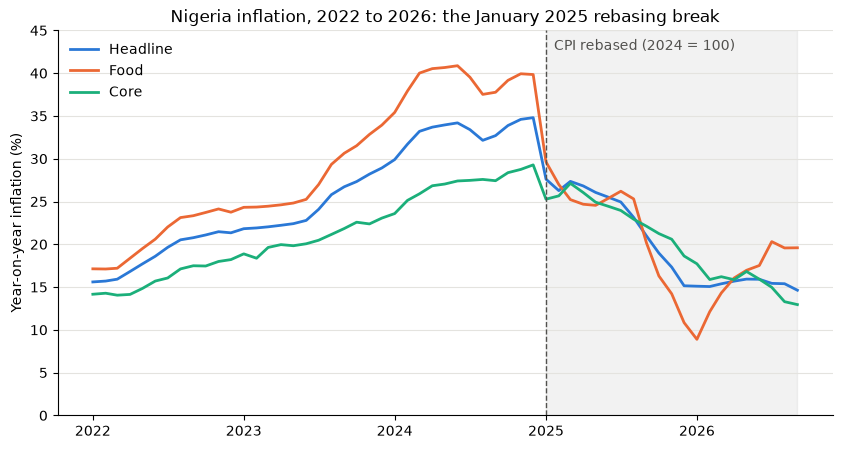

In [23]:
recent = macro.loc["2022-01":]
rebase_date = pd.Timestamp("2025-01-01")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(recent.index, recent["Headline"], color=HEADLINE_COLOUR, linewidth=2, label="Headline")
ax.plot(recent.index, recent["Food"], color=FOOD_COLOUR, linewidth=2, label="Food")
ax.plot(recent.index, recent["Core"], color=CORE_COLOUR, linewidth=2, label="Core")

# Rebasing marker: dashed line at January 2025, light shading for the rebased period
ax.axvline(rebase_date, color=REBASE_COLOUR, linestyle="--", linewidth=1)
ax.axvspan(rebase_date, recent.index.max(), color=REBASE_COLOUR, alpha=0.07)
ax.text(rebase_date, 44, "  CPI rebased (2024 = 100)", color=REBASE_COLOUR, va="top")

ax.set_ylim(0, 45)
ax.set_title("Nigeria inflation, 2022 to 2026: the January 2025 rebasing break")
ax.set_ylabel("Year-on-year inflation (%)")
ax.grid(axis="y", color="#e4e3df")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False)

fig.savefig("images/rebasing_break.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Headline inflation fell **7.19 points in a single month**, from 34.80% (December 2024) to 27.61% (January 2025). Food fell
10.21 points. That's the second-largest one-month move in the whole series, after July 2005, and it happened exactly when the measuring method
changed. After the break, inflation keeps falling steadily through 2025 and levels off at about 15% in 2026, while food inflation turns back up
to about 20%.

**What this means for modelling:** a model trained on 2003–2024 has never seen the new CPI, and a model trained on everything would read the
January 2025 drop as a real shock. As CLAUDE.md asks, we'll try both: **(a) train on 2003–2024 only**, and **(b) train on all data with the
`Rebased` dummy**, and compare them.

### 3.6 Final check

Same checks as in 2.6, on the cleaned table.

In [24]:
print("Rows, columns:", macro.shape)
print("Duplicate months:", macro.index.duplicated().sum())
print("\nBlank values per column:")
print(macro.isna().sum())

Rows, columns: (285, 6)
Duplicate months: 0

Blank values per column:
Headline      0
Food          0
Core          0
Crude_USD    81
USD_NGN       0
Rebased       0
dtype: int64


**Finding:** The cleaned table has 285 months and six columns (`Headline`, `Food`, `Core`, `Crude_USD`, `USD_NGN`, `Rebased`), no duplicate months
and no blanks except the **81 months of crude price before October 2009**, which we left blank on purpose. The data is ready for exploring in
Phase 4.

*Note:* `data/nigeria_macro.csv` stays as the raw API snapshot. The cleaning in this section runs again every time the notebook runs, so
each fix is visible and easy to change.

## 4. Exploratory data analysis (EDA)

EDA means looking at the data with charts and simple statistics *before* modelling, to understand its patterns.
What we learn here decides which models make sense. We answer four questions:

1. How has inflation moved since 2003, and what happened around the big peaks?
2. How does food inflation compare with headline inflation?
3. Is there a repeating pattern within the year (seasonality)?
4. Do crude oil prices and the naira/dollar rate **lead** inflation, and by how many months?

First, a small helper function. CLAUDE.md asks for the rebasing to be marked on **every** time chart. Instead of copying the same three lines
into every chart, we write them once as a function and call it.

In [25]:
def mark_rebasing(ax, label=True):
    # Draw the January 2025 CPI rebasing marker on a chart: dashed line + light shading afterwards
    rebase_date = pd.Timestamp("2025-01-01")
    ax.axvline(rebase_date, color=REBASE_COLOUR, linestyle="--", linewidth=1)
    ax.axvspan(rebase_date, macro.index.max(), color=REBASE_COLOUR, alpha=0.07)
    if label:
        # Place the label just below the top of the chart
        top = ax.get_ylim()[1]
        ax.text(rebase_date, top, " CPI\n rebased", color=REBASE_COLOUR, va="top", fontsize=9)


def tidy_chart(ax):
    # Light horizontal grid lines, no box on the top and right
    ax.grid(axis="y", color="#e4e3df")
    ax.set_axisbelow(True)  # draw grid lines behind bars and lines
    ax.spines[["top", "right"]].set_visible(False)

### 4.1 Long-run history, 2003–2026

**Question:** How have headline, food and core inflation moved since 2003? What were the major peaks, and what happened around them?

We mark three events on the chart: the **2016 recession** (oil prices crashed and the naira was devalued in June 2016), the **COVID-19** shock
(March 2020), and the **fuel subsidy removal and naira float** (May–June 2023).

In [26]:
# Highest headline inflation in each period, to see the peaks
periods = {
    "2003-2008": ("2003", "2008"),
    "2016 recession": ("2016", "2018"),
    "COVID-19": ("2020", "2021"),
    "Subsidy removal + float": ("2023", "2024"),
}
for name, (start, end) in periods.items():
    headline = macro.loc[start:end, "Headline"]
    print(f"{name:25} peak {headline.max():5.2f}% in {headline.idxmax():%B %Y}")

2003-2008                 peak 28.20% in August 2005
2016 recession            peak 18.72% in January 2017
COVID-19                  peak 18.17% in March 2021
Subsidy removal + float   peak 34.80% in December 2024


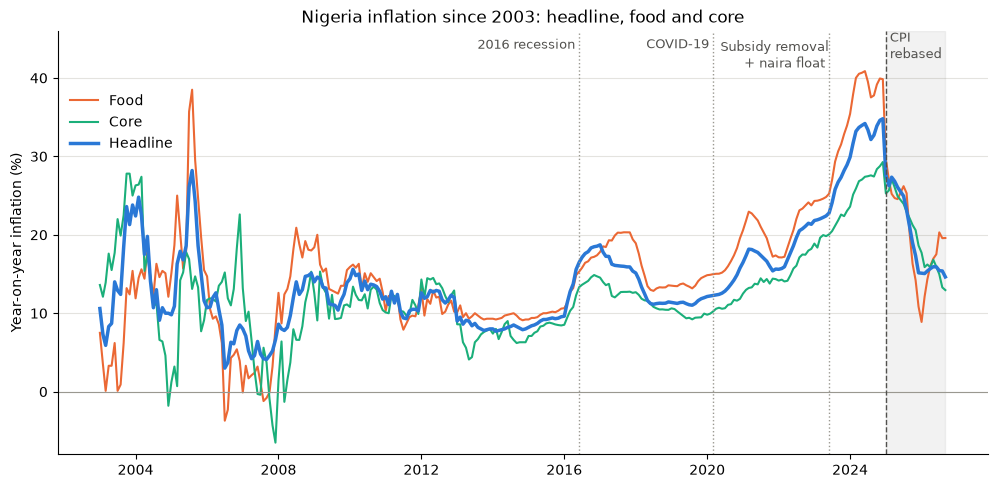

In [27]:
events = {
    "2016 recession": "2016-06-01",
    "COVID-19": "2020-03-01",
    "Subsidy removal\n+ naira float": "2023-06-01",
}

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(macro.index, macro["Food"], color=FOOD_COLOUR, linewidth=1.5, label="Food")
ax.plot(macro.index, macro["Core"], color=CORE_COLOUR, linewidth=1.5, label="Core")
ax.plot(macro.index, macro["Headline"], color=HEADLINE_COLOUR, linewidth=2.5, label="Headline")
ax.axhline(0, color="#9a9890", linewidth=0.8)

ax.set_ylim(-8, 46)
for label, date in events.items():
    ax.axvline(pd.Timestamp(date), color="#9a9890", linestyle=":", linewidth=1)
    ax.text(pd.Timestamp(date), 45, label + " ", ha="right", va="top", fontsize=9, color="#52514e")
mark_rebasing(ax)

ax.set_title("Nigeria inflation since 2003: headline, food and core")
ax.set_ylabel("Year-on-year inflation (%)")
tidy_chart(ax)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.88), frameon=False)

fig.savefig("images/long_run_inflation.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Nigeria's inflation comes in **waves**, and each recent wave has peaked higher than the one before.

- **2003–2008** was very jumpy: a peak of 28.2% in August 2005, and even negative food and core rates in some months.
- **2010–2015** was the calmest stretch, with headline mostly between 8% and 13% and below 10% for much of 2013–2015.
- **2016 recession:** the oil price crash and the June 2016 devaluation pushed headline from 9.6% (January 2016) to a peak of **18.72%** (January 2017).
- **COVID-19:** inflation climbed again to **18.17%** in March 2021.
- **Subsidy removal and naira float (mid-2023):** headline rose from 22.4% in May 2023 to **34.80%** in December 2024, the highest in the whole series. Food peaked at 40.87% in June 2024.

After the January 2025 rebasing, inflation fell through 2025 and has stayed at about **15%** through 2026. Notice that the last three waves all began soon after a fall in the naira. We test that link in 4.4.

### 4.2 Food vs headline: the gap

**Question:** Does food inflation usually run above headline inflation, and by how much?

Food is the biggest part of what Nigerian households spend money on, so food inflation hits poorer families hardest. We calculate the
**gap** = food inflation − headline inflation. When the gap is positive, food prices are rising faster than prices in general.

In [28]:
food_gap = macro["Food"] - macro["Headline"]

print(f"Average gap, 2003-2024:      {food_gap[:'2024'].mean():5.2f} points")
print(f"Average gap, 2023-2024:      {food_gap['2023':'2024'].mean():5.2f} points")
print(f"Average gap, 2025 onwards:   {food_gap['2025':].mean():5.2f} points")
print(f"Share of months with food above headline: {(food_gap > 0).mean():.0%}")
print(f"Latest gap ({food_gap.index[-1]:%B %Y}): {food_gap.iloc[-1]:.2f} points")

Average gap, 2003-2024:       1.13 points
Average gap, 2023-2024:       4.58 points
Average gap, 2025 onwards:   -0.18 points
Share of months with food above headline: 71%
Latest gap (September 2026): 4.96 points


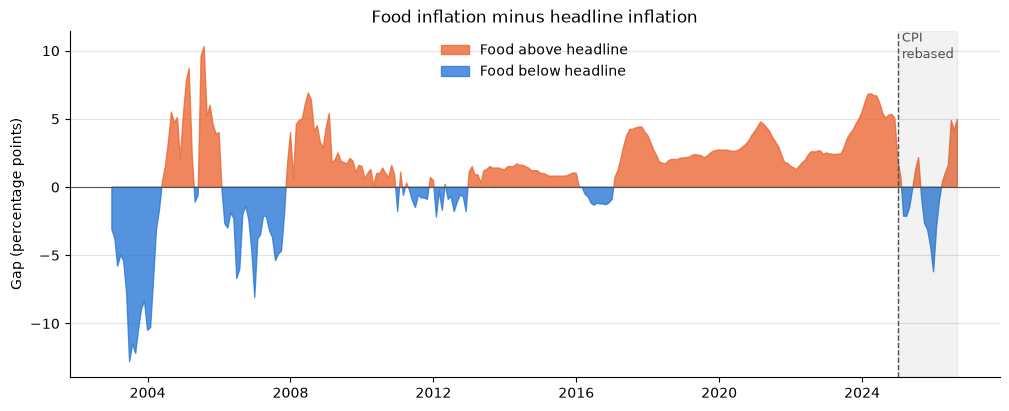

In [29]:
fig, ax = plt.subplots(figsize=(12, 4.5))

# Orange where food is above headline, blue where it's below
ax.fill_between(food_gap.index, food_gap, 0, where=food_gap >= 0, color=FOOD_COLOUR, alpha=0.8,
                interpolate=True, label="Food above headline")
ax.fill_between(food_gap.index, food_gap, 0, where=food_gap < 0, color=HEADLINE_COLOUR, alpha=0.8,
                interpolate=True, label="Food below headline")
ax.axhline(0, color="#52514e", linewidth=0.8)
mark_rebasing(ax)

ax.set_title("Food inflation minus headline inflation")
ax.set_ylabel("Gap (percentage points)")
tidy_chart(ax)
ax.legend(loc="upper center", frameon=False)

fig.savefig("images/food_headline_gap.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Food inflation is **usually higher** than headline: it was above headline in 71% of months, by **1.13 points** on average in 2003–2024. The gap widens in crises: about 4 points in 2017, about 5 in 2021, and **4.58 points on average in 2023–2024**.

After the rebasing, the pattern flipped for a while. Food fell *below* headline for most of 2025, with the gap reaching −6.21 points in January 2026, when food inflation was only 8.89%. But since early 2026, food inflation has **turned back up**. In September 2026 food was at 19.59% vs 14.63% for headline, a gap of **4.96 points**, as wide as during the 2023–2024 crisis. Food is the part of inflation to watch: if it keeps rising, the fall in headline inflation may not last.

### 4.3 Seasonality

**Question:** Is there a repeating pattern within the year, for example around Christmas or in the lean season before harvest?

**An important limit of our data first.** The feed gives **year-on-year** rates only: each month is compared with *the same month a year
earlier*. If prices always jump in December, December is compared with last December, which also jumped, so the seasonal effect
**mostly cancels out**. Year-on-year rates are "seasonally neutral" by design. (To measure true seasonality we'd need the month-on-month
rates or the CPI index itself, which NBS publishes but this feed doesn't include.)

So here is the check we *can* do: the **month-to-month change in the year-on-year rate**, averaged for each calendar month. If one calendar
month regularly pushes the rate up or down, its average will stand out from zero. We use 2003–2024 only, so the rebasing jump in January 2025
doesn't distort January's average.

In [30]:
change_in_rate = macro.loc[:"2024", "Headline"].diff()

# Group the changes by calendar month (1 = January ... 12 = December): average and typical spread
by_month = change_in_rate.groupby(change_in_rate.index.month).agg(["mean", "std"])
by_month.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month.round(2).T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
mean,0.02,0.10,0.16,-0.00,0.07,0.10,-0.09,0.16,0.15,0.32,-0.04,0.16
std,1.11,1.22,1.57,1.41,1.10,2.06,2.31,0.99,1.91,1.80,1.09,1.10


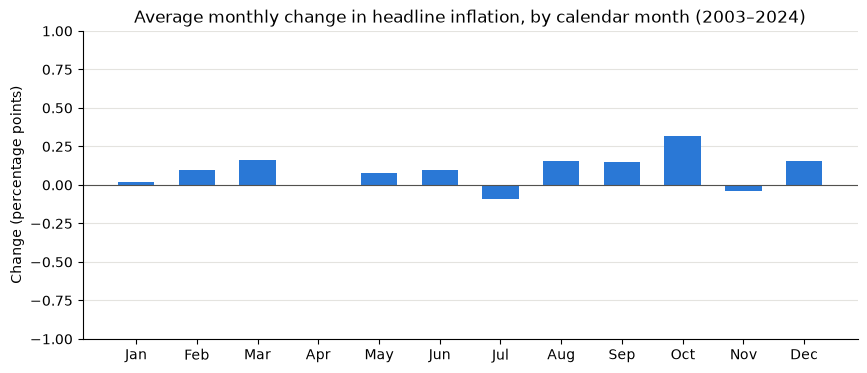

In [31]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_month.index, by_month["mean"], color=HEADLINE_COLOUR, width=0.6)
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_ylim(-1, 1)

ax.set_title("Average monthly change in headline inflation, by calendar month (2003–2024)")
ax.set_ylabel("Change (percentage points)")
tidy_chart(ax)

fig.savefig("images/seasonality.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** There's **no meaningful seasonal pattern** in the year-on-year rate. Every calendar month's average change is small, between −0.09 and +0.32 points. In comparison, the change in any single month typically varies by 1–2 points (the `std` row). October has the largest average (+0.32), but that's small next to the noise.

This is what we expected, because year-on-year rates cancel out most seasonal effects. **For modelling:** seasonal terms probably won't help when we forecast the year-on-year rate. In Phase 7 we'll test whether SARIMA's seasonal part helps, rather than assume it. Measuring the festive-season or lean-season pattern properly would need NBS's month-on-month rates, which this feed doesn't have.

### 4.4 Drivers: do crude oil and the naira lead inflation?

**Question:** Do changes in crude oil prices and the naira/dollar rate show up in inflation later, and at what lag (1, 3, 6 or 12 months)?

**Step 1: compare like with like.** Inflation is a year-on-year **% change**. Comparing it with the *level* of the exchange rate (₦1,500)
would be comparing a speed with a distance. So we turn the drivers into year-on-year % changes too: "how much more naira does a dollar cost
than a year ago?" and "how much more does a barrel of oil cost than a year ago?" `pct_change(12)` does exactly this: it compares each month
with 12 months earlier.

**Step 2: look at them together.** We can't put inflation and the naira on one chart with two different y-axes, because that makes it too
easy to see links that aren't there. Instead we stack three small charts that share the same time axis.

In [32]:
# Year-on-year % change of each driver
macro["USD_NGN_yoy"] = macro["USD_NGN"].pct_change(12) * 100
macro["Crude_yoy"] = macro["Crude_USD"].pct_change(12) * 100

# Around the June 2023 float: the naira's fall shows up as a big jump in USD_NGN_yoy
macro[["Headline", "USD_NGN_yoy", "Crude_yoy"]].loc["2023-04":"2023-09"].round(1)

,Headline,USD_NGN_yoy,Crude_yoy
Date,,,
2023-04-01,22.2,10.8,-18.7
2023-05-01,22.4,11.0,-34.4
2023-06-01,22.8,46.4,-40.5
2023-07-01,24.1,85.4,-31.8
2023-08-01,25.8,81.4,-16.0
2023-09-01,26.7,77.6,5.3


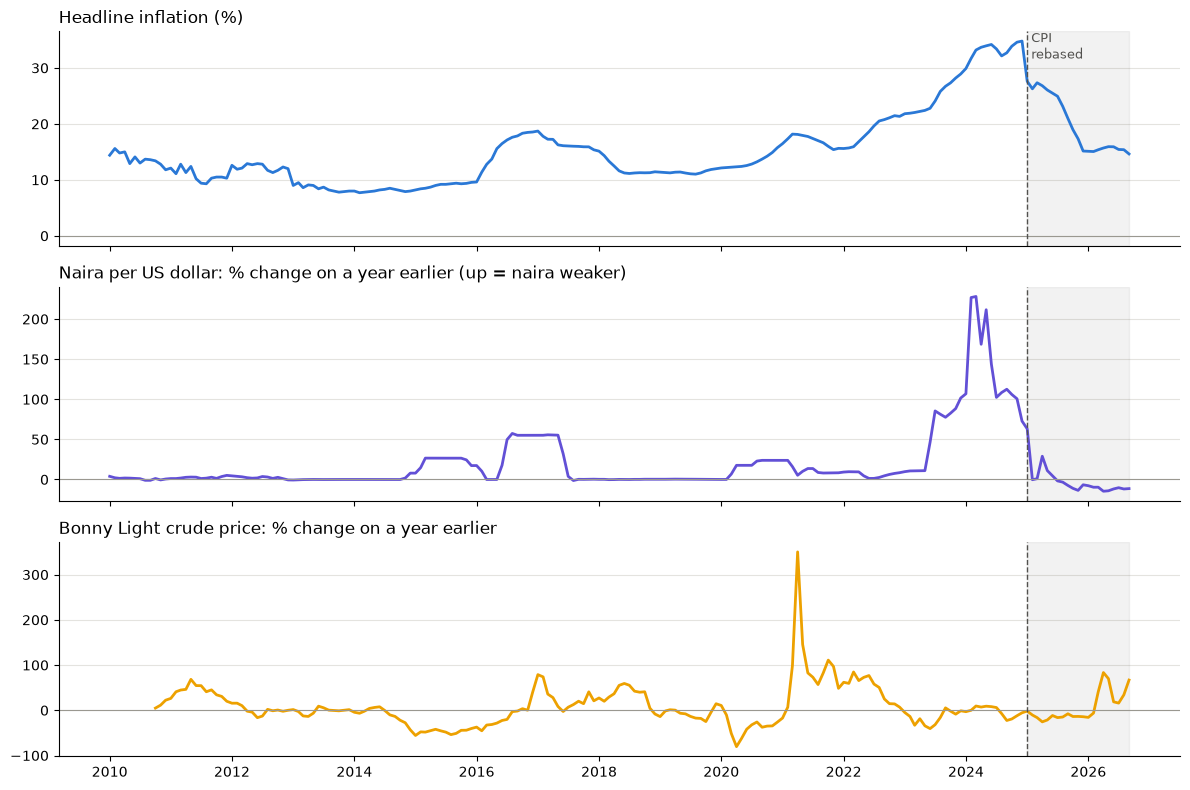

In [33]:
recent = macro.loc["2010":]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(recent.index, recent["Headline"], color=HEADLINE_COLOUR, linewidth=2)
axes[0].set_title("Headline inflation (%)", loc="left")

axes[1].plot(recent.index, recent["USD_NGN_yoy"], color=FX_COLOUR, linewidth=2)
axes[1].set_title("Naira per US dollar: % change on a year earlier (up = naira weaker)", loc="left")

axes[2].plot(recent.index, recent["Crude_yoy"], color=CRUDE_COLOUR, linewidth=2)
axes[2].set_title("Bonny Light crude price: % change on a year earlier", loc="left")

for ax in axes:
    ax.axhline(0, color="#9a9890", linewidth=0.8)
    tidy_chart(ax)
    mark_rebasing(ax, label=(ax is axes[0]))

fig.tight_layout()
fig.savefig("images/drivers.png", dpi=150, bbox_inches="tight")
plt.show()

**Step 3: measure the link at different lags.** A **lag** means shifting a series later in time. `shift(3)` moves the exchange rate 3 months
forward, so each month's inflation is lined up with the exchange rate from **3 months earlier**. If the naira's fall *leads* inflation,
the link should be stronger at some lag than at lag 0.

We measure the link with the **correlation** (`corr`), a number from −1 to +1:
- **+1:** the two always move up and down together
- **0:** no straight-line link
- **−1:** one goes up when the other goes down

We use data up to December 2024 only, so the rebasing break doesn't distort the result.

In [34]:
before_rebasing = macro.loc[:"2024"]
lags = [0, 1, 3, 6, 12]

rows = []
for lag in lags:
    rows.append({
        "Lag (months)": lag,
        "Naira fall vs Headline": before_rebasing["Headline"].corr(before_rebasing["USD_NGN_yoy"].shift(lag)),
        "Naira fall vs Food": before_rebasing["Food"].corr(before_rebasing["USD_NGN_yoy"].shift(lag)),
        "Naira fall vs Core": before_rebasing["Core"].corr(before_rebasing["USD_NGN_yoy"].shift(lag)),
        "Crude change vs Headline": before_rebasing["Headline"].corr(before_rebasing["Crude_yoy"].shift(lag)),
    })
lag_correlations = pd.DataFrame(rows).set_index("Lag (months)")
lag_correlations.round(2)

,Naira fall vs Headline,Naira fall vs Food,Naira fall vs Core,Crude change vs Headline
Lag (months),,,,
0,0.72,0.68,0.63,0.10
1,0.73,0.68,0.63,0.09
3,0.71,0.66,0.64,0.06
6,0.66,0.62,0.58,0.03
12,0.52,0.49,0.48,0.01


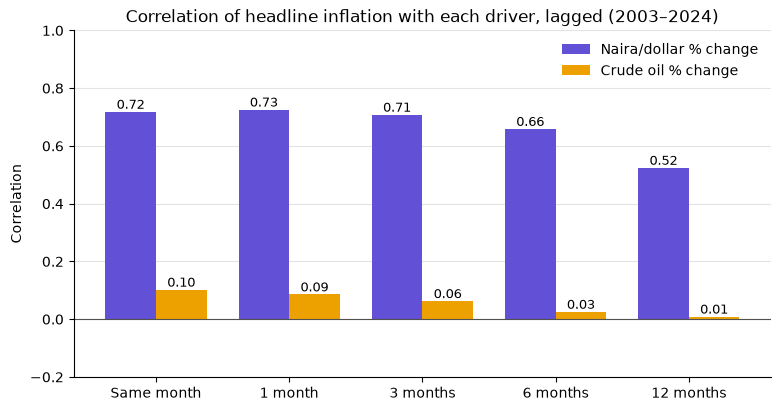

In [35]:
fig, ax = plt.subplots(figsize=(9, 4.5))
positions = range(len(lags))
bar_width = 0.38

fx_bars = ax.bar([p - bar_width / 2 for p in positions], lag_correlations["Naira fall vs Headline"],
                 width=bar_width, color=FX_COLOUR, label="Naira/dollar % change")
crude_bars = ax.bar([p + bar_width / 2 for p in positions], lag_correlations["Crude change vs Headline"],
                    width=bar_width, color=CRUDE_COLOUR, label="Crude oil % change")
ax.bar_label(fx_bars, fmt="%.2f", fontsize=9)
ax.bar_label(crude_bars, fmt="%.2f", fontsize=9)

ax.set_xticks(list(positions), ["Same month", "1 month", "3 months", "6 months", "12 months"])
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_ylim(-0.2, 1)
ax.set_title("Correlation of headline inflation with each driver, lagged (2003–2024)")
ax.set_ylabel("Correlation")
tidy_chart(ax)
ax.legend(loc="upper right", frameon=False)

fig.savefig("images/lag_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** - **The naira matters, a lot.** Headline inflation and the naira's year-on-year fall have a correlation of **0.72** in the same month, rising slightly to **0.73 at a 1-month lag**, the strongest. It's 0.71 at 3 months, 0.66 at 6 months, and fades to 0.52 at 12 months. Food (0.68) and core (0.63) follow the same pattern. The stacked chart shows it clearly: the 2016, 2020–21 and 2023–24 inflation waves each **began with a jump in the naira/dollar rate**. Since 2025, the naira has been *strengthening* (the dollar costs 10–15% fewer naira than a year earlier), which fits with inflation falling.
- **Crude oil barely matters, at any lag** (correlation 0.10 or less). One likely reason is that until mid-2023, petrol pump prices were fixed by the fuel subsidy, so world oil prices didn't reach Nigerian shoppers. Oil also pulls both ways for Nigeria: a higher oil price brings in more dollars (which supports the naira), but makes imported fuel dearer. Worth noting: in September 2026, crude was **67% more expensive** than a year earlier, and petrol is no longer subsidised, so this link may be stronger in future than in the past.
- **For modelling:** the lagged naira change (1 and 3 months) is our most promising extra feature. Crude oil looks weak, but we'll still test it rather than drop it on a hunch.

**A warning about correlation.** Correlation shows that two things move together. It doesn't prove that one *causes* the other. Both series
here change slowly, so this month's value is close to last month's, and that makes correlations at nearby lags look almost the same. The real
test is in Phase 6: does adding the lagged naira rate **actually lower the forecast error** on months the model hasn't seen?

## 5. Baselines

**Question:** How well can the *simplest possible* forecast do? Every model we build later has to beat this, or it isn't worth using.

A **baseline** is a forecast rule so simple it needs no learning. If a clever model can't beat "next month = this month", the cleverness is
adding nothing. In this section we:

1. Split the data by time into a **training set** and a **test set**
2. Learn the error measure we'll use for every model: **MAE**
3. Build three baselines and score them in two ways: **1 month ahead** and **12 months ahead**

### 5.1 Train/test split, by time

To judge a forecast fairly, we must test it on months it has **never seen**. So we hold back the **last 12 months** as the **test set**, and
build models only on the months before them (the **training set**).

**We never shuffle time-series data.** In many machine-learning projects, rows are shuffled randomly before splitting. Here that would be
cheating: the model would train on, say, March 2026 and then "forecast" February 2026, using knowledge of the future. Real forecasting
always goes forwards in time, so our split does too.

In [36]:
TEST_MONTHS = 12

train = macro.iloc[:-TEST_MONTHS]  # every month except the last 12
test = macro.iloc[-TEST_MONTHS:]   # the last 12 months, hidden from the models

print(f"Training set: {train.index.min():%b %Y} to {train.index.max():%b %Y} ({len(train)} months)")
print(f"Test set:     {test.index.min():%b %Y} to {test.index.max():%b %Y} ({len(test)} months)")
print(f"Rebased months in the training set: {train['Rebased'].sum()}")

Training set: Jan 2003 to Sep 2025 (273 months)
Test set:     Oct 2025 to Sep 2026 (12 months)
Rebased months in the training set: 9


**Finding:** We train on **273 months** (January 2003 to September 2025) and test on **12 months** (October 2025 to September 2026).
The whole test year comes after the rebasing, but only **9 of the training months** (January–September 2025) do. Models will have very little
"new CPI" data to learn from, which is why we'll compare different ways of handling the break in Phases 6–7.

### 5.2 Measuring error: MAE

For each test month, the **error** is *actual − forecast*. Some errors are positive (we forecast too low) and some negative (too high).
If we simply averaged them, they'd cancel out, and a terrible forecast could look perfect. So we take the **absolute value** first,
dropping the minus sign, and then average. That's the **Mean Absolute Error (MAE)**:

> MAE = the average size of the miss

Our inflation rates are in %, so MAE is in **percentage points**. An MAE of 0.5 means "on average, the forecast was off by half a point",
for example forecasting 15.0% when the actual was 15.5%. Lower is better.

In [37]:
def mae(actual, forecast):
    # Mean Absolute Error: the average size of the forecast miss, ignoring direction
    errors = actual - forecast
    return errors.abs().mean()


# A tiny example: misses of +1, -2 and +0.5 points -> average size (1 + 2 + 0.5) / 3 = 1.17
example_actual = pd.Series([15.0, 14.0, 13.5])
example_forecast = pd.Series([14.0, 16.0, 13.0])
print(f"Example MAE: {mae(example_actual, example_forecast):.2f} points")

Example MAE: 1.17 points


### 5.3 Three baselines, forecasting 1 month ahead

Each test month, we forecast that month using only the months **before** it:

| Baseline | Rule | pandas |
|---|---|---|
| **Naive** | Next month = this month | `shift(1)` |
| **Moving average (3m)** | Next month = average of the last 3 months | `rolling(3).mean().shift(1)` |
| **Seasonal naive** | Next month = the same month a year earlier | `shift(12)` |

`shift(1)` moves the series one month later, so each month's row holds the *previous* month's value. That's how we make sure a forecast only
uses information **available at the time**. `rolling(3).mean()` averages each month with the two before it. We then `shift(1)` that too, so
the average never includes the month being forecast.

In [38]:
def one_month_ahead_baselines(series):
    # Forecast each month using only the months before it
    return pd.DataFrame({
        "Naive": series.shift(1),                                  # last month's value
        "Moving average (3m)": series.rolling(3).mean().shift(1),  # average of the previous 3 months
        "Seasonal naive": series.shift(12),                        # same month, one year earlier
    })


headline_one_month = one_month_ahead_baselines(macro["Headline"]).loc[test.index]
headline_one_month.insert(0, "Actual", test["Headline"])
headline_one_month.round(2)

,Actual,Naive,Moving average (3m),Seasonal naive
Date,,,,
2025-10-01,18.97,20.98,23.02,33.88
2025-11-01,17.33,18.97,21.03,34.60
2025-12-01,15.15,17.33,19.09,34.80
2026-01-01,15.10,15.15,17.15,27.61
2026-02-01,15.06,15.10,15.86,26.27
2026-03-01,15.38,15.06,15.10,27.35
2026-04-01,15.69,15.38,15.18,26.82
2026-05-01,15.93,15.69,15.38,26.06
2026-06-01,15.91,15.93,15.67,25.50


Now we score each baseline, for headline **and** food. We collect every score in a list called `scores`, and in Phase 8 we'll add
every other model's scores to the same list to compare them all.

In [39]:
scores = []  # one entry per (model, target, horizon); we keep adding to this in later phases

for target in ["Headline", "Food"]:
    forecasts = one_month_ahead_baselines(macro[target]).loc[test.index]
    for model in forecasts.columns:
        scores.append({
            "Model": model,
            "Target": target,
            "Horizon": "1 month ahead",
            "MAE": mae(test[target], forecasts[model]),
        })

pd.DataFrame(scores).round(2)

,Model,Target,Horizon,MAE
0,Naive,Headline,1 month ahead,0.67
1,Moving average (3m),Headline,1 month ahead,1.49
2,Seasonal naive,Headline,1 month ahead,11.83
3,Naive,Food,1 month ahead,1.95
4,Moving average (3m),Food,1 month ahead,3.62
5,Seasonal naive,Food,1 month ahead,13.36


### 5.4 The same baselines, forecasting 12 months ahead

Forecasting 1 month ahead is the easy case, because we always know last month's value. Our final forecast (Phase 9) looks **6–12 months**
ahead, so we also test that harder case. We stand at the **end of the training data (September 2025)**, and forecast all 12 test months at once,
without seeing any of them:

- **Naive:** every future month = September 2025's value (a flat line)
- **Moving average (3m):** every future month = the average of July–September 2025 (also flat)
- **Seasonal naive:** each future month = the same month a year earlier (October 2024 – September 2025, all already known)

In [40]:
def twelve_months_ahead_baselines(train_series, future_dates):
    # Stand at the end of the training data and forecast every future month at once
    return pd.DataFrame({
        "Naive": train_series.iloc[-1],                         # last known value, repeated
        "Moving average (3m)": train_series.iloc[-3:].mean(),   # average of the last 3 known months, repeated
        "Seasonal naive": train_series.iloc[-12:].to_numpy(),   # the last 12 known months, in order
    }, index=future_dates)


for target in ["Headline", "Food"]:
    forecasts = twelve_months_ahead_baselines(train[target], test.index)
    for model in forecasts.columns:
        scores.append({
            "Model": model,
            "Target": target,
            "Horizon": "12 months ahead",
            "MAE": mae(test[target], forecasts[model]),
        })

# One row per model, one column per (horizon, target)
scores_table = pd.DataFrame(scores).pivot_table(index="Model", columns=["Horizon", "Target"], values="MAE")
scores_table.round(2)

Horizon             1 month ahead          12 months ahead         
Target                       Food Headline            Food Headline
Model                                                              
Moving average (3m)          3.62     1.49            8.33     7.19
Naive                        1.95     0.67            4.63     5.15
Seasonal naive              13.36    11.83           13.36    11.83

### 5.5 Forecast vs actual

Each chart shows the actual headline rate (black) and each baseline's forecast for the test year. Left: 1 month ahead. Right: 12 months ahead.

Each model gets its own colour, and keeps it in every later chart, so you can always tell models apart.

In [41]:
# One fixed colour per model, reused in every later forecast chart
MODEL_COLOURS = {
    "Naive": "#e87ba4",                # pink
    "Moving average (3m)": "#008300",  # green
    "Seasonal naive": "#9a9890",       # grey
}
ACTUAL_COLOUR = "#0b0b0b"              # near-black

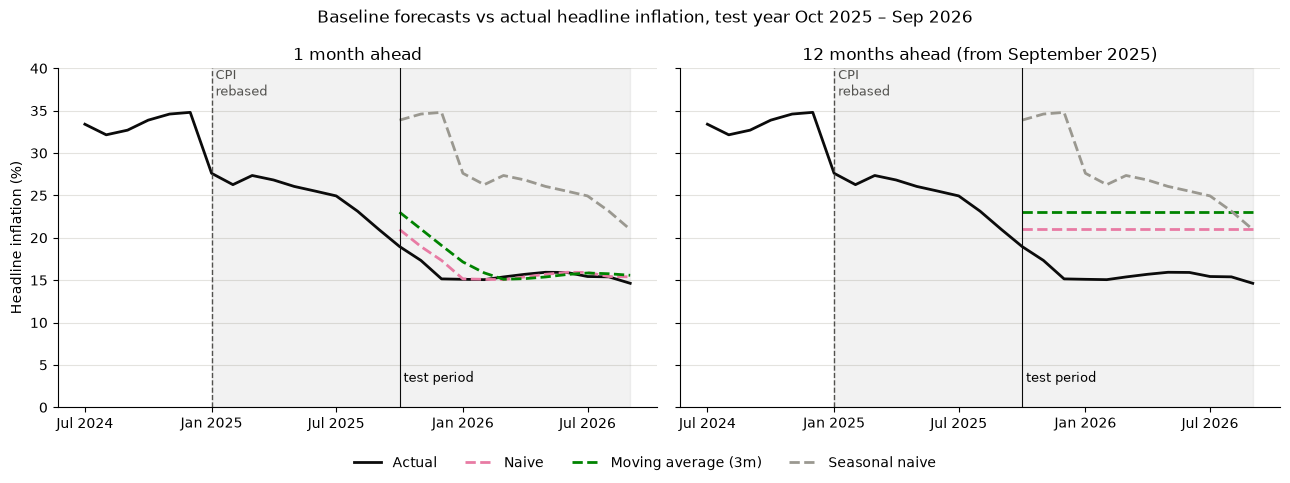

In [42]:
import matplotlib.dates as mdates  # tools for formatting dates on chart axes

history = macro.loc["2024-07":, "Headline"]
headline_twelve_months = twelve_months_ahead_baselines(train["Headline"], test.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
panels = [
    (axes[0], headline_one_month, "1 month ahead"),
    (axes[1], headline_twelve_months, "12 months ahead (from September 2025)"),
]

for ax, forecasts, title in panels:
    ax.plot(history.index, history, color=ACTUAL_COLOUR, linewidth=2, label="Actual")
    for model, colour in MODEL_COLOURS.items():
        ax.plot(forecasts.index, forecasts[model], color=colour, linewidth=2, linestyle="--", label=model)

    ax.set_ylim(0, 40)
    ax.axvline(test.index[0], color=ACTUAL_COLOUR, linewidth=0.8)
    ax.text(test.index[0], 3, " test period", fontsize=9)
    mark_rebasing(ax)
    ax.set_title(title)
    # One date label every 6 months, written like "Jan 2025"
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    tidy_chart(ax)

axes[0].set_ylabel("Headline inflation (%)")
# One shared legend underneath both charts
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Baseline forecasts vs actual headline inflation, test year Oct 2025 – Sep 2026")
fig.tight_layout(rect=[0, 0.07, 1, 1])  # leave room at the bottom for the legend

fig.savefig("images/baselines_headline.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:**

**1 month ahead, the naive forecast is excellent:** an MAE of just **0.67 points** for headline and **1.95** for food. Inflation moves slowly
from month to month, so "same as last month" is rarely far off. The 3-month moving average is **worse** (1.49 and 3.62): when inflation is
falling fast, as in late 2025, averaging in older and higher months makes the forecast lag behind.

**Seasonal naive is terrible** (MAE about 12–13 points). This teaches two things. First, a year-on-year rate *already* compares with last year,
so copying last year's rate is the wrong idea for this kind of data. Second, it copies October–December 2024 values (33.88%–34.80%), which were
measured on the **old CPI basket**. That's the rebasing break hurting a forecast directly.

**12 months ahead is much harder.** Naive's MAE jumps to **5.15 points** for headline: it kept forecasting September 2025's 20.98% while
inflation fell to about 15%. For food it's 4.63, but partly by luck: food dropped to 8.89% and then climbed back near its starting point,
so a flat line ended up close again by the end.

**The scores to beat:**

| | 1 month ahead | 12 months ahead |
|---|---|---|
| Headline | **0.67** | **5.15** |
| Food | **1.95** | **4.63** |

Beating 0.67 at 1 month ahead will be hard. The 12-month horizon is where a model has room to add real value.

## 6. Regression with lag features

**Question:** Can a model that learns from past inflation, and from the naira and oil, beat the naive forecast?

**Linear regression** finds the best weighted sum of some inputs (**features**) to predict an output (the **target**):

> forecast = intercept + weight₁ × feature₁ + weight₂ × feature₂ + …

"Best" means the weights that make the squared errors on the training data as small as possible. The weights are called **coefficients**,
and you can read them: a coefficient of 0.5 means "if this feature goes up by 1, the forecast goes up by 0.5".

We use `LinearRegression` from **scikit-learn**, the standard Python machine-learning library.

In [43]:
from sklearn.linear_model import LinearRegression

### 6.1 Lag features: turning the past into inputs

A regression needs features *for each month*. Our features are **lags**, values from earlier months, built with `shift()`
like the baselines:

- **Own lags:** inflation 1, 2 and 3 months ago (`Headline_lag1`, `Headline_lag2`, `Headline_lag3`)
- **Driver lags:** the naira's year-on-year change, and crude oil's, from 1 and 3 months ago (the lags that looked strongest in 4.4)

Every feature is shifted by **at least one month**, so the model only ever uses information that was **available at the time**. That's the
"no future values" rule from CLAUDE.md.

In [44]:
def make_features(data, target, drivers=(), dummies=()):
    # Build the model inputs for each month, using only values from earlier months
    features = pd.DataFrame(index=data.index)

    # The target's own past: 1, 2 and 3 months ago
    for lag in [1, 2, 3]:
        features[f"{target}_lag{lag}"] = data[target].shift(lag)

    # Each driver's past: 1 and 3 months ago
    for driver in drivers:
        for lag in [1, 3]:
            features[f"{driver}_lag{lag}"] = data[driver].shift(lag)

    # Dummy columns are known in advance (they mark calendar events), so they aren't shifted
    for dummy in dummies:
        features[dummy] = data[dummy]

    return features


# Example: the features the model would see when forecasting October 2025
example = make_features(macro, "Headline", drivers=["USD_NGN_yoy"])
example.loc[["2025-10-01"]].round(2)

,Headline_lag1,Headline_lag2,Headline_lag3,USD_NGN_yoy_lag1,USD_NGN_yoy_lag3
Date,,,,,
2025-10-01,20.98,23.14,24.94,-7.44,-1.78


To forecast **October 2025**, the model sees headline inflation for September, August and July 2025 (20.98, 23.14, 24.94), and the naira's
year-on-year change from September and July 2025. Everything it uses was published before October 2025.

### 6.2 First model: own lags only

We start with the simplest version: forecast headline inflation from its own last 3 months. We train on **2003–2024 only**, the first way of
handling the break from CLAUDE.md. That way the training data contains no rebased months at all.

`.dropna()` removes the first few months, which have no lagged values yet (there's no "3 months ago" for March 2003).

In [45]:
features = make_features(macro, "Headline")
training_rows = features.loc[:"2024-12-01"].dropna().index

model = LinearRegression()
model.fit(features.loc[training_rows], macro.loc[training_rows, "Headline"])

print(f"Trained on {training_rows.min():%b %Y} to {training_rows.max():%b %Y} ({len(training_rows)} months)")
print(f"Intercept: {model.intercept_:.2f}")
pd.Series(model.coef_, index=features.columns, name="Coefficient").round(3)

Trained on Apr 2003 to Dec 2024 (261 months)
Intercept: 0.39


Headline_lag1    1.170
Headline_lag2   -0.150
Headline_lag3   -0.042
Name: Coefficient, dtype: float64

In [46]:
# 1 month ahead: for each test month, use the real values of the months before it
one_month_forecast = pd.Series(model.predict(features.loc[test.index]), index=test.index)
print(f"Regression (lags only), 1 month ahead MAE: {mae(test['Headline'], one_month_forecast):.2f}")
print(f"Naive baseline,         1 month ahead MAE: 0.67")

Regression (lags only), 1 month ahead MAE: 0.57
Naive baseline,         1 month ahead MAE: 0.67


**Finding:** The model learned: forecast ≈ **1.17 × last month − 0.15 × two months ago − 0.04 × three months ago + 0.39**.
In plain words: "mostly last month's value, plus a little **momentum** (if inflation rose last month, it tends to keep rising)". The three
coefficients add up to just under 1 (0.98), so over many months the forecast drifts slowly back toward the long-run average.

Its 1-month-ahead MAE is **0.57**, a small but real improvement on naive (0.67).

### 6.3 Adding the drivers: naira and oil

Now we test the question from Phase 4: **do the naira and oil improve forecasts?** We fit three versions and compare them on the test year.
To avoid copying the same code three times, we put fitting and scoring into small functions.

Note: crude oil's year-on-year change only exists from October 2010 (the crude feed starts in October 2009), so the model with oil trains on
**2011–2024**, a shorter period than the others.

In [47]:
def fit_regression(target, drivers=(), dummies=(), train_end="2024-12-01"):
    # Fit a linear regression on all complete months up to train_end
    features = make_features(macro, target, drivers, dummies)
    training_rows = features.loc[:train_end].dropna().index
    model = LinearRegression()
    model.fit(features.loc[training_rows], macro.loc[training_rows, target])
    return model, features, training_rows


def forecast_one_month_ahead(model, features):
    # Forecast each test month from the real values of the months before it
    return pd.Series(model.predict(features.loc[test.index]), index=test.index)


feature_sets = {
    "Lags only": [],
    "Lags + naira": ["USD_NGN_yoy"],
    "Lags + naira + oil": ["USD_NGN_yoy", "Crude_yoy"],
}

rows = []
for name, drivers in feature_sets.items():
    model, features, training_rows = fit_regression("Headline", drivers)
    forecast = forecast_one_month_ahead(model, features)
    rows.append({
        "Features": name,
        "Training starts": f"{training_rows.min():%b %Y}",
        "1-month MAE": mae(test["Headline"], forecast),
    })

pd.DataFrame(rows).round(2)

,Features,Training starts,1-month MAE
0,Lags only,Apr 2003,0.57
1,Lags + naira,Apr 2004,0.54
2,Lags + naira + oil,Jan 2011,0.60


In [48]:
# What did the model learn about the naira?
model, features, _ = fit_regression("Headline", ["USD_NGN_yoy"])
pd.Series(model.coef_, index=features.columns, name="Coefficient").round(3)

Headline_lag1       1.196
Headline_lag2      -0.216
Headline_lag3      -0.034
USD_NGN_yoy_lag1    0.013
USD_NGN_yoy_lag3   -0.004
Name: Coefficient, dtype: float64

**Finding:** Adding the naira improves the 1-month forecast slightly (MAE **0.54**, vs 0.57 with lags only). Its coefficient looks tiny,
**0.013**, but the naira's year-on-year change is measured in %, and it can be huge: when the naira was 100% weaker than a year earlier
(2024), that adds about 1.3 points to the forecast, **every month**.

Adding oil makes the forecast **worse** (0.60). That agrees with Phase 4: crude oil has little link with Nigerian inflation. It also costs us
seven years of training data, because oil data starts later.

### 6.4 Handling the rebasing break: three ways

CLAUDE.md asks us to compare **(a) training on 2003–2024 only** with **(b) training on all data plus the `Rebased` dummy**. Let's do that
with the "lags + naira" model, and add a third option that turns out to matter:

- **(a) 2003–2024 only:** what we've done so far. The model never sees a rebased month.
- **(b) All data + `Rebased` dummy:** train up to September 2025. `Rebased` is 0 before January 2025 and 1 from then on (a **step**).
- **(c) All data + `Rebase_jump` dummy:** `Rebase_jump` is 1 **only in January 2025**, 0 in every other month (a one-month **pulse**).

Why might (b) and (c) behave differently? Think about what the model sees. It forecasts each month mostly from **last month**. In January
2025, last month was 34.80% and the actual was 27.61%: a huge surprise. But in February 2025, last month was already the *new* level, so
nothing was unusual any more. The rebasing caused a **one-month surprise**, not a surprise every month. A step dummy tells the model
"subtract something in *every* month after 2024", which is the wrong shape.

In [49]:
# A one-month pulse: 1 only in January 2025
macro["Rebase_jump"] = (macro.index == "2025-01-01").astype(int)

break_options = {
    "(a) 2003-2024 only": dict(dummies=[], train_end="2024-12-01"),
    "(b) All data + Rebased": dict(dummies=["Rebased"], train_end=train.index[-1]),
    "(c) All data + Rebase_jump": dict(dummies=["Rebase_jump"], train_end=train.index[-1]),
}

rows = []
for name, options in break_options.items():
    model, features, _ = fit_regression("Headline", ["USD_NGN_yoy"], **options)
    forecast = forecast_one_month_ahead(model, features)
    dummy_coefficient = model.coef_[-1] if options["dummies"] else None
    rows.append({"Option": name, "Dummy coefficient": dummy_coefficient, "1-month MAE": mae(test["Headline"], forecast)})

pd.DataFrame(rows).round(2)

,Option,Dummy coefficient,1-month MAE
0,(a) 2003-2024 only,NaN,0.54
1,(b) All data + Rebased,-0.56,0.72
2,(c) All data + Rebase_jump,-6.70,0.56


**Finding:**

- **(b) The step dummy hurts** (MAE 0.72, worse than even naive). Its coefficient, about −0.56, means "subtract 0.56 points from *every*
  month after 2024". The model had to fit one −7 point surprise using a dummy that is "on" for 9 months, and the result fits none of them well.
- **(c) The pulse dummy works.** Its coefficient is about **−6.7**, very close to the real January 2025 drop (−7.19). The model learned
  "January 2025 was a one-off", and its forecasts are as good as (a).
- **(a) and (c) give almost the same result,** because a pulse dummy basically lets the model ignore that one strange month.

**Lesson:** a dummy has to match the *shape* of the event **as the model sees it**. For a model built on lags, a permanent level shift shows up
as a one-month jump.

### 6.5 Forecasting 12 months ahead, one step at a time

The 1-month forecast always had last month's *real* value. Twelve months ahead, we don't: to forecast November 2025 from September 2025, we
need October 2025's inflation, which we don't know yet.

The standard trick is a **recursive forecast**:
1. Forecast October 2025.
2. Treat that forecast as if it were October's real value, and use it to forecast November.
3. Repeat, month by month, for 12 months.

**The drivers have the same problem:** we don't know the naira's future either. We make the simplest assumption: **the naira's year-on-year
change stays at its last known value** (September 2025) for the whole forecast. That's an assumption, and if the naira had suddenly
collapsed in 2026, the forecast would have been wrong.

In [50]:
def forecast_recursive(model, target, drivers=(), dummies=(), last_known_date=None, months=12):
    # Forecast `months` months after last_known_date, feeding each forecast back in as "last month"
    history = macro.loc[:last_known_date].copy()

    for step in range(months):
        next_date = history.index[-1] + pd.DateOffset(months=1)

        # Start the new month as a copy of the last month: drivers and dummies keep their last known values
        new_row = history.iloc[[-1]].copy()
        new_row.index = [next_date]
        history = pd.concat([history, new_row])

        # Build the features for the new month (they only use earlier months) and forecast it
        next_features = make_features(history, target, drivers, dummies).iloc[[-1]]
        history.loc[next_date, target] = model.predict(next_features)[0]

    return history[target].iloc[-months:]


model, features, _ = fit_regression("Headline", ["USD_NGN_yoy"])
twelve_month_forecast = forecast_recursive(model, "Headline", ["USD_NGN_yoy"], last_known_date=train.index[-1])

pd.DataFrame({"Actual": test["Headline"], "Forecast": twelve_month_forecast}).round(2)

,Actual,Forecast
2025-10-01,18.97,19.80
2025-11-01,17.33,18.93
2025-12-01,15.15,18.22
2026-01-01,15.10,17.61
2026-02-01,15.06,17.07
2026-03-01,15.38,16.57
2026-04-01,15.69,16.11
2026-05-01,15.93,15.69
2026-06-01,15.91,15.30
2026-07-01,15.43,14.94


### 6.6 Scoring every version, for headline and food

Now we score all five versions, for both targets and both horizons, and add them to the `scores` list from Phase 5.

In [51]:
regression_setups = {
    "Regression: lags": dict(drivers=[], dummies=[], train_end="2024-12-01"),
    "Regression: lags + naira": dict(drivers=["USD_NGN_yoy"], dummies=[], train_end="2024-12-01"),
    "Regression: lags + naira + oil": dict(drivers=["USD_NGN_yoy", "Crude_yoy"], dummies=[], train_end="2024-12-01"),
    "Regression: lags + naira, all data + Rebased": dict(drivers=["USD_NGN_yoy"], dummies=["Rebased"], train_end=train.index[-1]),
    "Regression: lags + naira, all data + Rebase_jump": dict(drivers=["USD_NGN_yoy"], dummies=["Rebase_jump"], train_end=train.index[-1]),
}

regression_forecasts = {}  # keep each forecast for charts: key = (model name, target, horizon)

for target in ["Headline", "Food"]:
    for name, setup in regression_setups.items():
        model, features, _ = fit_regression(target, setup["drivers"], setup["dummies"], setup["train_end"])

        one_month = forecast_one_month_ahead(model, features)
        twelve_months = forecast_recursive(model, target, setup["drivers"], setup["dummies"], last_known_date=train.index[-1])

        regression_forecasts[(name, target, "1 month ahead")] = one_month
        regression_forecasts[(name, target, "12 months ahead")] = twelve_months
        scores.append({"Model": name, "Target": target, "Horizon": "1 month ahead", "MAE": mae(test[target], one_month)})
        scores.append({"Model": name, "Target": target, "Horizon": "12 months ahead", "MAE": mae(test[target], twelve_months)})

scores_table = pd.DataFrame(scores).pivot_table(index="Model", columns=["Horizon", "Target"], values="MAE")
scores_table.round(2)

Horizon                                          1 month ahead           \
Target                                                    Food Headline   
Model                                                                     
Moving average (3m)                                       3.62     1.49   
Naive                                                     1.95     0.67   
Regression: lags                                          1.91     0.57   
Regression: lags + naira                                  1.94     0.54   
Regression: lags + naira + oil                            1.73     0.60   
Regression: lags + naira, all data + Rebase_jump          1.91     0.56   
Regression: lags + naira, all data + Rebased              2.29     0.72   
Seasonal naive                                           13.36    11.83   

Horizon                                          12 months ahead           
Target                                                      Food Headline  
Model                                                                      
Moving average (3m)                                         8.33     7.19  
Naive                                                       4.63     5.15  
Regression: lags                                            4.87     4.05  
Regression: lags + naira                                    3.96     1.17  
Regression: lags + naira + oil                              4.57     6.15  
Regression: lags + naira, all data + Rebase_jump            3.91     1.26  
Regression: lags + naira, all data + Rebased                7.31     2.78  
Seasonal naive                                             13.36    11.83

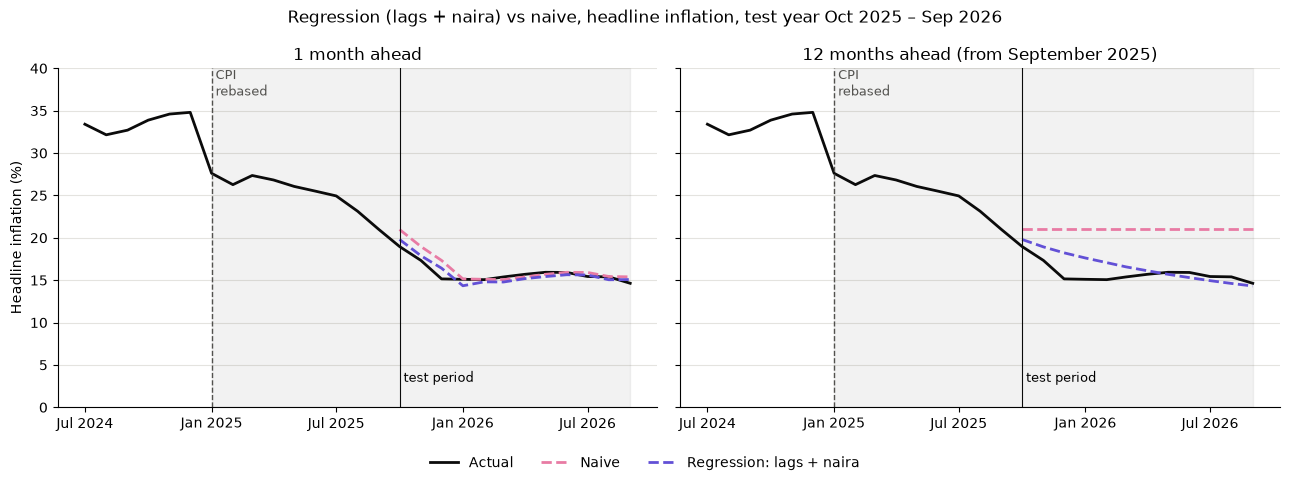

In [52]:
MODEL_COLOURS["Regression: lags + naira"] = "#6250d6"  # violet

best_name = "Regression: lags + naira"
history = macro.loc["2024-07":, "Headline"]
naive_one_month = one_month_ahead_baselines(macro["Headline"]).loc[test.index, "Naive"]
naive_twelve_months = twelve_months_ahead_baselines(train["Headline"], test.index)["Naive"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
panels = [
    (axes[0], "1 month ahead", naive_one_month),
    (axes[1], "12 months ahead", naive_twelve_months),
]

for ax, horizon, naive_forecast in panels:
    ax.plot(history.index, history, color=ACTUAL_COLOUR, linewidth=2, label="Actual")
    ax.plot(test.index, naive_forecast, color=MODEL_COLOURS["Naive"], linewidth=2, linestyle="--", label="Naive")
    ax.plot(test.index, regression_forecasts[(best_name, "Headline", horizon)],
            color=MODEL_COLOURS[best_name], linewidth=2, linestyle="--", label=best_name)

    ax.set_ylim(0, 40)
    ax.axvline(test.index[0], color=ACTUAL_COLOUR, linewidth=0.8)
    ax.text(test.index[0], 3, " test period", fontsize=9)
    mark_rebasing(ax)
    ax.set_title(horizon if horizon == "1 month ahead" else "12 months ahead (from September 2025)")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    tidy_chart(ax)

axes[0].set_ylabel("Headline inflation (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Regression (lags + naira) vs naive, headline inflation, test year Oct 2025 – Sep 2026")
fig.tight_layout(rect=[0, 0.07, 1, 1])

fig.savefig("images/regression_headline.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** **Headline: the regression with lags + naira beats naive at both horizons.**

| Headline MAE | 1 month ahead | 12 months ahead |
|---|---|---|
| Naive | 0.67 | 5.15 |
| Regression: lags + naira | **0.54** | **1.17** |

One month ahead the gain is modest (about 20% smaller errors). **Twelve months ahead the gain is big:** naive stayed flat at 20.98%, while the regression glided down from 19.8% to about 14.3%, close to what actually happened. Why? In September 2025, the naira was **7.4% stronger** than a year earlier, and the model learned from 20 years of data that a strengthening naira pulls inflation down.

**Three honest caveats:**
1. The 12-month forecast assumed the naira's year-on-year change would **stay at −7.4%**. In reality it stayed between about −7% and −15%, so the assumption happened to hold. If the naira had weakened in 2026, this forecast would have been badly wrong.
2. The forecast is **still falling** at the end (14.31% vs actual 14.63%), because the held-constant naira keeps pushing it down every month. Over longer horizons, that assumption gets less and less realistic.
3. One test year is a **small sample**: 12 months. A model can look good partly by luck.

**Food is harder.** One month ahead, the regressions are only slightly better than naive (1.73–1.94 vs 1.95). Twelve months ahead, lags + naira does better (3.96 vs 4.63), but not dramatically. Oil helps food one month ahead (1.73) but hurts twelve months ahead (4.57). An extra feature that helps in one test and hurts in the other isn't one to trust.

**The break:** the step dummy (b) is the worst regression for both targets, especially food 12 months ahead (7.31). Options (a) and (c) give nearly identical results.

**Carried forward to Phase 8:** *Regression: lags + naira* is our best model so far, and the **naira** is the driver that matters.

## 7. ARIMA and SARIMA

**Question:** Can a classic time-series model beat the naive baseline and our regression?

**ARIMA** is the most widely used statistical model for forecasting a single time series. Its name lists its three parts, each with a number:

| Part | Number | Plain meaning |
|---|---|---|
| **AR**: AutoRegressive | **p** | Use the last *p* values of the series (like the lags in our regression) |
| **I**: Integrated | **d** | First take the *d*-th difference (month-to-month change) of the series, so it has no trend |
| **MA**: Moving Average | **q** | Also use the last *q* forecast **errors**: "last month I under-forecast, so adjust up a bit" |

So ARIMA(1,1,0) means: model the month-to-month **change** (d=1), using the previous change (p=1), with no error terms (q=0).

**SARIMA** adds a **S**easonal version of the same three parts, repeated every 12 months. **SARIMAX** also allows e**X**ternal inputs,
like the naira. All three live in one `statsmodels` class: `SARIMAX`.

In [53]:
import warnings

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

# statsmodels needs to know the data is monthly ("MS" = month start)
macro = macro.asfreq("MS")

### 7.1 Does the series need differencing? (the "d")

ARIMA's AR and MA parts assume the series is **stationary**: it wobbles around a fixed average, with a steady amount of wobble, and no trend.
Inflation levels clearly aren't: they drift for years (10% in 2015, 34% in 2024).

The **Augmented Dickey-Fuller (ADF) test** checks this. It gives a **p-value**:

- **p below 0.05:** good evidence the series *is* stationary
- **p above 0.05:** we can't say it's stationary, so we **difference** it (work with month-to-month changes) and test again

We test on 2003–2024 only, so the rebasing jump doesn't confuse the test.

In [54]:
headline_train = macro.loc[:"2024-12", "Headline"]
headline_change = headline_train.diff().dropna()  # month-to-month change in the rate

# adfuller returns several numbers; [1] is the p-value (result_object=False keeps the classic output format)
print(f"ADF p-value, headline level:  {adfuller(headline_train, result_object=False)[1]:.3f}")
print(f"ADF p-value, monthly change:  {adfuller(headline_change, result_object=False)[1]:.3f}")

ADF p-value, headline level:  0.992
ADF p-value, monthly change:  0.013


**Finding:** The level has a p-value of **0.99**, so it's clearly not stationary. The monthly change has **0.013**, below 0.05, so it is.
Differencing once is enough: **d = 1**.

### 7.2 Reading the ACF and PACF (the "p" and "q")

Two standard charts help choose p and q:

- **ACF (autocorrelation function):** how strongly this month's change is correlated with the change 1, 2, 3… months earlier.
- **PACF (partial autocorrelation):** the same, but counting only the *direct* link at each lag, after removing the effect of the lags in between.

The blue shaded band is the "could just be chance" zone. Bars sticking out of it are real patterns. Rough rule: a PACF that cuts off after lag *p*
suggests AR(*p*), and an ACF that cuts off after lag *q* suggests MA(*q*).

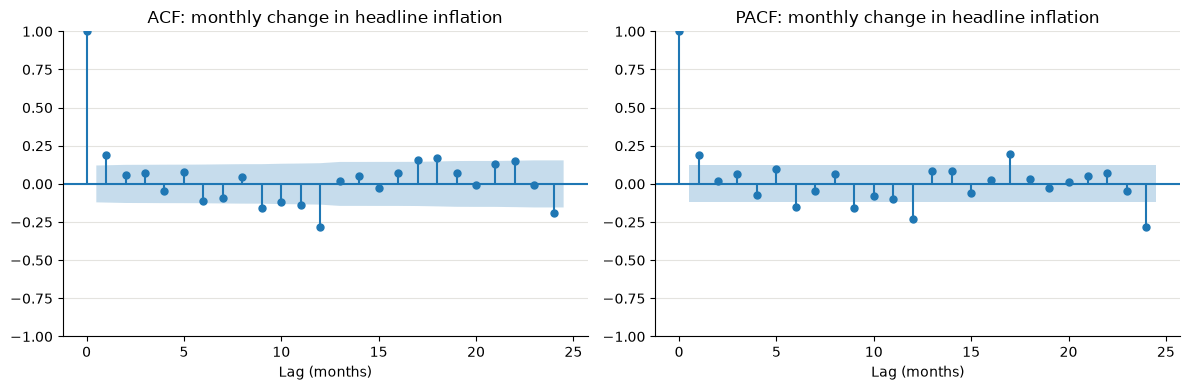

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(headline_change, lags=24, ax=axes[0], title="ACF: monthly change in headline inflation")
plot_pacf(headline_change, lags=24, ax=axes[1], title="PACF: monthly change in headline inflation")
for ax in axes:
    ax.set_xlabel("Lag (months)")
    tidy_chart(ax)
fig.tight_layout()
fig.savefig("images/acf_pacf.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Among the short lags, only **lag 1** (about 0.19) stands out in both charts, then the PACF cuts off. That points to a small
**AR(1)** term, so **ARIMA(1,1,0)** is our starting candidate. A few longer lags (9, 17, 18) poke just outside the band. With 24 bars and a
95% band, one or two crossing by chance is expected, so we don't chase them.

The clearest pattern is the **negative spikes at lags 12 and 24** (about −0.28 and −0.19). That's not seasonality. It's a **base effect**, a
side-effect of year-on-year rates. This month's year-on-year rate rises with this month's price jump, but *falls* when last year's same-month
jump drops out of the comparison. So a big rise in the rate tends to be followed by a fall exactly 12 months later. A seasonal model may pick
this up, and we'll test that in 7.5.

### 7.3 Choosing the orders with AIC

The ACF and PACF give a starting point, but it's common to also try a small grid of orders and compare them with **AIC** (Akaike Information
Criterion). AIC rewards a model for fitting the training data well, but **penalises extra parameters**. Lower AIC is better.

Two rules keep this honest:

1. We choose using **training data only** (AIC and the ACF/PACF), **never** the test set. Choosing by test score would be cheating: the
   test set would no longer be "unseen".
2. We check each fit **converged**. Fitting ARIMA means numerically searching for the best coefficients, and sometimes the search gives up.
   A model that didn't converge can't be trusted.

To avoid repeating code, we write helper functions. The fitting prints optimiser warnings for some orders. We hide those and check convergence
ourselves in the table.

In [56]:
def fit_arima(target, order, seasonal_order=(0, 0, 0, 0), exog_columns=(), train_end="2024-12-01", start=None):
    # Fit a (S)ARIMA(X) model on months from `start` to `train_end`
    y = macro.loc[start:train_end, target]
    exog = macro.loc[start:train_end, list(exog_columns)] if exog_columns else None
    model = SARIMAX(y, exog=exog, order=order, seasonal_order=seasonal_order)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # hide optimiser messages; we check convergence ourselves
        return model.fit(disp=False)


def has_converged(result):
    # True if the coefficient search finished properly
    return result.mle_retvals["converged"]

In [57]:
rows = []
for p in range(4):
    for q in range(4):
        result = fit_arima("Headline", order=(p, 1, q))
        rows.append({"Order": f"({p},1,{q})", "AIC": result.aic, "Converged": has_converged(result)})

order_search = pd.DataFrame(rows).sort_values("AIC")
order_search.round(1).head(8)

,Order,AIC,Converged
15,"(3,1,3)",922.8,False
4,"(1,1,0)",955.6,True
1,"(0,1,1)",956.1,True
7,"(1,1,3)",956.2,True
10,"(2,1,2)",956.4,True
13,"(3,1,1)",956.9,True
3,"(0,1,3)",956.9,True
5,"(1,1,1)",957.3,True


**Finding:** The lowest AIC belongs to **(3,1,3)**, but it **did not converge**: the coefficient search gave up, so its AIC can't be trusted, and we drop it. (Its coefficients are also large and opposite in sign, a typical sign of an unstable model.)

Among the models that converged, **(1,1,0) has the lowest AIC (955.6)**. Many others are within about 2 points of it, and a difference that small means "no real difference". When models are this close, we pick the **simplest** one. It also matches what the ACF and PACF suggested. **Our model: ARIMA(1,1,0).**

### 7.4 Fitting ARIMA(1,1,0) and forecasting with an interval

We fit on 2003–2024 (like regression option (a)) and forecast in our two ways:

- **1 month ahead:** `apply()` runs the fitted model, with the **same coefficients**, over the full data, and `get_prediction()` reads off
  its forecast for each test month made from the months before it.
- **12 months ahead:** `apply()` the model to the data up to September 2025 (again, same coefficients), then `get_forecast(12)`.

ARIMA also gives us something the regression didn't: a **forecast interval**. An **80% interval** is a range that should contain the actual
value about 8 times out of 10, *if the model's assumptions are right*. Intervals widen the further ahead we look, because uncertainty builds
up month after month.

In [58]:
def arima_one_month_ahead(result, target, exog_columns=(), start=None):
    # Run the fitted model (same coefficients) over all the data; read off its 1-step forecasts for the test months
    y = macro.loc[start:, target]
    exog = macro.loc[start:, list(exog_columns)] if exog_columns else None
    full = result.apply(y, exog=exog)
    return full.get_prediction(start=test.index[0]).predicted_mean


def arima_twelve_months_ahead(result, target, exog_columns=(), start=None):
    # Update the model with data up to September 2025 (same coefficients), then forecast 12 months with an 80% interval
    last_known = train.index[-1]
    y = macro.loc[start:last_known, target]
    exog = macro.loc[start:last_known, list(exog_columns)] if exog_columns else None
    updated = result.apply(y, exog=exog)

    # Future values of the external inputs: we only know the past, so hold each at its last known value
    future_exog = None
    if exog_columns:
        future_exog = pd.DataFrame(index=test.index)
        for column in exog_columns:
            if column == "USD_NGN_yoy_lag1":
                future_exog[column] = macro.loc[last_known, "USD_NGN_yoy"]  # naira's change assumed to stay the same
            else:
                future_exog[column] = macro.loc[last_known, column]         # dummies keep their last value

    forecast = updated.get_forecast(steps=len(test), exog=future_exog)
    interval = forecast.conf_int(alpha=0.2)  # alpha=0.2 -> 80% interval
    interval.columns = ["lower", "upper"]
    return forecast.predicted_mean, interval

In [59]:
arima_result = fit_arima("Headline", order=(1, 1, 0))
print(arima_result.params.round(3))

arima_one_month = arima_one_month_ahead(arima_result, "Headline")
arima_twelve_months, arima_interval = arima_twelve_months_ahead(arima_result, "Headline")

inside = (test["Headline"] >= arima_interval["lower"]) & (test["Headline"] <= arima_interval["upper"])
print(f"\n1 month ahead MAE:   {mae(test['Headline'], arima_one_month):.2f}   (naive 0.67, regression 0.54)")
print(f"12 months ahead MAE: {mae(test['Headline'], arima_twelve_months):.2f}   (naive 5.15, regression 1.17)")
print(f"Actual values inside the 80% interval: {inside.sum()} of {len(test)}")

pd.DataFrame({"Actual": test["Headline"], "Forecast": arima_twelve_months}).join(arima_interval).round(2)

ar.L1     0.194
sigma2    2.182
dtype: float64

1 month ahead MAE:   0.60   (naive 0.67, regression 0.54)
12 months ahead MAE: 4.64   (naive 5.15, regression 1.17)
Actual values inside the 80% interval: 8 of 12


,Actual,Forecast,lower,upper
2025-10-01,18.97,20.56,18.67,22.45
2025-11-01,17.33,20.48,17.53,23.43
2025-12-01,15.15,20.47,16.71,24.22
2026-01-01,15.10,20.46,16.03,24.89
2026-02-01,15.06,20.46,15.45,25.47
2026-03-01,15.38,20.46,14.93,26.00
2026-04-01,15.69,20.46,14.45,26.47
2026-05-01,15.93,20.46,14.01,26.92
2026-06-01,15.91,20.46,13.59,27.33
2026-07-01,15.43,20.46,13.20,27.72


**Finding:** The model learned one coefficient: **ar.L1 = 0.19**, so this month's change ≈ 0.19 × last month's change. It has a little momentum, but not much.

- **1 month ahead: MAE 0.60.** That's better than naive (0.67), but not as good as the regression (0.54).
- **12 months ahead: MAE 4.64.** That's barely better than naive (5.15). Look at the forecast column: after a month or two the momentum dies out, and the forecast goes **flat at about 20.5%**. ARIMA(1,1,0) has no idea where inflation "should" be heading. It only knows recent changes, so far ahead it becomes "naive plus a little".
- **The interval** starts narrow (18.7–22.5% for October 2025) and widens to **12.5–28.4%** by September 2026. That's honest about how uncertain a year-ahead forecast is. **8 of the 12** actual values landed inside the 80% interval, a bit fewer than the 9–10 we'd expect. The four misses (November 2025 – February 2026) were months when inflation fell **faster** than in a normal month.

### 7.5 Three variations: the break, seasonality and the naira

**(1) The rebasing break, again.** In Phase 6, the `Rebased` step dummy failed and the one-month pulse worked. ARIMA with d=1 models the
**monthly change**, and a step in the *level* becomes a one-month pulse in the *change*. So here, CLAUDE.md's step dummy should have exactly
the right shape. We fit on **all** training data (to September 2025) with `Rebased` as an external input.

**(2) Seasonality.** SARIMA adds seasonal terms with a 12-month cycle: `seasonal_order=(1, 0, 1, 12)` means one seasonal AR term and one
seasonal MA term, linking each month to the same month a year earlier.

**(3) The naira.** SARIMAX with last month's naira change (`USD_NGN_yoy_lag1`) as an external input. The naira's year-on-year change only exists
from January 2004, so this model starts in February 2004.

In [60]:
macro["USD_NGN_yoy_lag1"] = macro["USD_NGN_yoy"].shift(1)  # last month's value: known at forecast time

rebased_result = fit_arima("Headline", (1, 1, 0), exog_columns=["Rebased"], train_end=train.index[-1])
seasonal_result = fit_arima("Headline", (1, 1, 0), seasonal_order=(1, 0, 1, 12))
naira_result = fit_arima("Headline", (1, 1, 0), exog_columns=["USD_NGN_yoy_lag1"], start="2004-02-01")

print(f"Rebased dummy coefficient: {rebased_result.params['Rebased']:.2f}  (actual January 2025 drop: -7.19)")
print(f"Naira coefficient:         {naira_result.params['USD_NGN_yoy_lag1']:.3f}")
print(f"AIC without / with seasonal terms: {arima_result.aic:.1f} / {seasonal_result.aic:.1f}")

Rebased dummy coefficient: -6.97  (actual January 2025 drop: -7.19)
Naira coefficient:         0.009
AIC without / with seasonal terms: 955.6 / 887.2


### 7.6 Scoring every version, for headline and food

In [61]:
arima_setups = {
    "ARIMA(1,1,0)": dict(order=(1, 1, 0)),
    "ARIMA(1,1,0), all data + Rebased": dict(order=(1, 1, 0), exog_columns=["Rebased"], train_end=train.index[-1]),
    "SARIMA(1,1,0)(1,0,1,12)": dict(order=(1, 1, 0), seasonal_order=(1, 0, 1, 12)),
    "SARIMAX(1,1,0) + naira": dict(order=(1, 1, 0), exog_columns=["USD_NGN_yoy_lag1"], start="2004-02-01"),
}

arima_forecasts = {}  # key = (model name, target, horizon); for 12 months we also keep the interval

for target in ["Headline", "Food"]:
    for name, setup in arima_setups.items():
        result = fit_arima(target, **setup)
        exog_columns = setup.get("exog_columns", ())
        start = setup.get("start")

        one_month = arima_one_month_ahead(result, target, exog_columns, start)
        twelve_months, interval = arima_twelve_months_ahead(result, target, exog_columns, start)
        inside = (test[target] >= interval["lower"]) & (test[target] <= interval["upper"])

        arima_forecasts[(name, target, "1 month ahead")] = one_month
        arima_forecasts[(name, target, "12 months ahead")] = (twelve_months, interval)
        scores.append({"Model": name, "Target": target, "Horizon": "1 month ahead", "MAE": mae(test[target], one_month)})
        scores.append({"Model": name, "Target": target, "Horizon": "12 months ahead", "MAE": mae(test[target], twelve_months),
                       "Inside 80% interval": f"{inside.sum()} of {len(test)}"})

arima_scores = pd.DataFrame(scores)
arima_scores = arima_scores[arima_scores["Model"].str.contains("ARIMA")]
arima_scores.pivot_table(index="Model", columns=["Horizon", "Target"], values="MAE").round(2)

Horizon                          1 month ahead          12 months ahead  \
Target                                    Food Headline            Food   
Model                                                                     
ARIMA(1,1,0)                              1.74     0.60            4.01   
ARIMA(1,1,0), all data + Rebased          1.73     0.60            3.99   
SARIMA(1,1,0)(1,0,1,12)                   2.44     0.93            3.61   
SARIMAX(1,1,0) + naira                    1.73     0.58            3.93   

Horizon                                    
Target                           Headline  
Model                                      
ARIMA(1,1,0)                         4.64  
ARIMA(1,1,0), all data + Rebased     4.63  
SARIMA(1,1,0)(1,0,1,12)              3.05  
SARIMAX(1,1,0) + naira               4.44

In [62]:
# How often did the actual value land inside the 80% interval (12 months ahead)?
arima_scores.dropna(subset=["Inside 80% interval"]).pivot(index="Model", columns="Target", values="Inside 80% interval")

Target,Food,Headline
Model,,
"ARIMA(1,1,0)",8 of 12,8 of 12
"ARIMA(1,1,0), all data + Rebased",8 of 12,8 of 12
"SARIMA(1,1,0)(1,0,1,12)",10 of 12,10 of 12
"SARIMAX(1,1,0) + naira",7 of 12,8 of 12


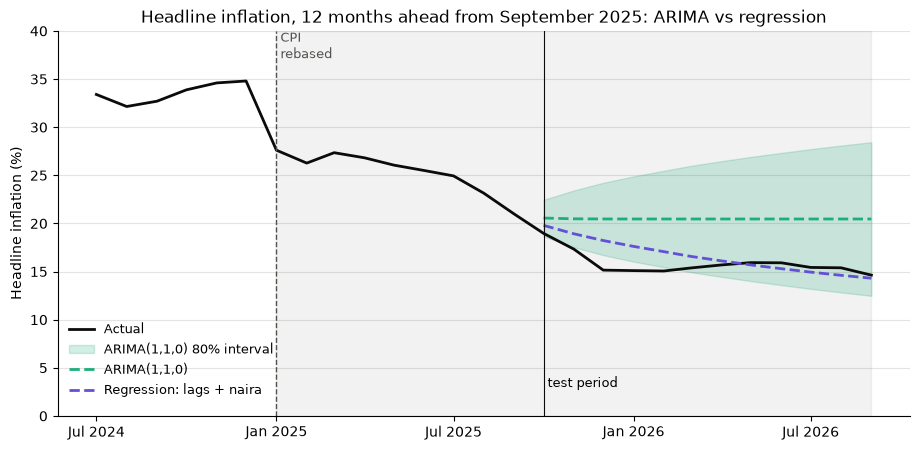

In [63]:
MODEL_COLOURS["ARIMA(1,1,0)"] = "#1baf7a"  # green

history = macro.loc["2024-07":, "Headline"]
arima_mean, arima_band = arima_forecasts[("ARIMA(1,1,0)", "Headline", "12 months ahead")]
regression_mean = regression_forecasts[("Regression: lags + naira", "Headline", "12 months ahead")]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(history.index, history, color=ACTUAL_COLOUR, linewidth=2, label="Actual")
ax.fill_between(test.index, arima_band["lower"], arima_band["upper"], color=MODEL_COLOURS["ARIMA(1,1,0)"], alpha=0.2,
                label="ARIMA(1,1,0) 80% interval")
ax.plot(test.index, arima_mean, color=MODEL_COLOURS["ARIMA(1,1,0)"], linewidth=2, linestyle="--", label="ARIMA(1,1,0)")
ax.plot(test.index, regression_mean, color=MODEL_COLOURS["Regression: lags + naira"], linewidth=2, linestyle="--",
        label="Regression: lags + naira")

ax.set_ylim(0, 40)
ax.axvline(test.index[0], color=ACTUAL_COLOUR, linewidth=0.8)
ax.text(test.index[0], 3, " test period", fontsize=9)
mark_rebasing(ax)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Headline inflation, 12 months ahead from September 2025: ARIMA vs regression")
ax.set_ylabel("Headline inflation (%)")
tidy_chart(ax)
ax.legend(loc="lower left", bbox_to_anchor=(0, 0.02), frameon=False, fontsize=9)

fig.savefig("images/arima_headline.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** **The break:** CLAUDE.md's `Rebased` step dummy **works for ARIMA**. Its coefficient is **−6.97**, almost exactly the real −7.19 drop, and the results match the 2003–2024 version (4.63 vs 4.64). It's the same dummy that failed in the regression. The difference is that ARIMA models the monthly *change*, where a level step becomes a one-month pulse. **Always match the dummy to what the model actually sees.**

**Seasonality (SARIMA):** the seasonal terms cut AIC sharply (887 vs 956). Their strong coefficient (seasonal MA ≈ −0.84) is the **base effect** from 7.2. Twelve months ahead, SARIMA is the best ARIMA version (headline **3.05**, food **3.61**), and 10 of 12 actuals fell inside its interval. But one month ahead it's **worse than naive** for both headline (0.93 vs 0.67) and food (2.44 vs 1.95). A model that helps at one horizon and hurts at the other is **not a reliable improvement**.

**The naira (SARIMAX):** only a small gain (headline 0.58 and 4.44). Why so much less than in the regression? With d=1, SARIMAX links the *change* in inflation to the *change* in the naira variable. We hold the naira steady in the forecast, so it adds no further push, and the forecast still goes flat. The regression instead linked the *level* of inflation to the naira's year-on-year change, so a steadily strong naira kept pulling inflation down month after month.

**Overall:**

| Headline MAE | 1 month ahead | 12 months ahead |
|---|---|---|
| Naive | 0.67 | 5.15 |
| Best ARIMA version | 0.58 (SARIMAX + naira) | 3.05 (SARIMA) |
| Regression: lags + naira | **0.54** | **1.17** |

The regression is still best for headline. ARIMA's big contribution is **forecast intervals**, which we'll need for the final forecast in Phase 9.

## 8. Model comparison

**Question:** Which model forecasts best on data it hasn't seen, and does it beat the naive baseline?

Every model from Phases 5–7 added its MAE to the `scores` list. Now we put them all side by side. Then we ask a harder question: is **one test
year** enough to pick a winner?

### 8.1 The comparison table

One row per model, with the MAE for each target and horizon. The last column counts how many of the four tests each model wins against the naive
baseline. Rows are sorted by the 12-month headline score, the one closest to our final goal.

In [64]:
comparison = pd.DataFrame(scores).pivot_table(index="Model", columns=["Target", "Horizon"], values="MAE")
comparison = comparison[[("Headline", "1 month ahead"), ("Headline", "12 months ahead"),
                         ("Food", "1 month ahead"), ("Food", "12 months ahead")]]

# How many of the 4 tests does each model win against naive? (lower MAE = better)
naive_scores = comparison.loc["Naive"]
comparison[("Beats naive (of 4)", "")] = (comparison < naive_scores).sum(axis=1)
comparison.loc["Naive", ("Beats naive (of 4)", "")] = None  # naive can't beat itself

comparison = comparison.sort_values(("Headline", "12 months ahead"))
comparison.round(2)

Target                                                Headline  \
Horizon                                          1 month ahead   
Model                                                            
Regression: lags + naira                                  0.54   
Regression: lags + naira, all data + Rebase_jump          0.56   
Regression: lags + naira, all data + Rebased              0.72   
SARIMA(1,1,0)(1,0,1,12)                                   0.93   
Regression: lags                                          0.57   
SARIMAX(1,1,0) + naira                                    0.58   
ARIMA(1,1,0), all data + Rebased                          0.60   
ARIMA(1,1,0)                                              0.60   
Naive                                                     0.67   
Regression: lags + naira + oil                            0.60   
Moving average (3m)                                       1.49   
Seasonal naive                                           11.83   

Target                                                            \
Horizon                                          12 months ahead   
Model                                                              
Regression: lags + naira                                    1.17   
Regression: lags + naira, all data + Rebase_jump            1.26   
Regression: lags + naira, all data + Rebased                2.78   
SARIMA(1,1,0)(1,0,1,12)                                     3.05   
Regression: lags                                            4.05   
SARIMAX(1,1,0) + naira                                      4.44   
ARIMA(1,1,0), all data + Rebased                            4.63   
ARIMA(1,1,0)                                                4.64   
Naive                                                       5.15   
Regression: lags + naira + oil                              6.15   
Moving average (3m)                                         7.19   
Seasonal naive                                             11.83   

Target                                                    Food  \
Horizon                                          1 month ahead   
Model                                                            
Regression: lags + naira                                  1.94   
Regression: lags + naira, all data + Rebase_jump          1.91   
Regression: lags + naira, all data + Rebased              2.29   
SARIMA(1,1,0)(1,0,1,12)                                   2.44   
Regression: lags                                          1.91   
SARIMAX(1,1,0) + naira                                    1.73   
ARIMA(1,1,0), all data + Rebased                          1.73   
ARIMA(1,1,0)                                              1.74   
Naive                                                     1.95   
Regression: lags + naira + oil                            1.73   
Moving average (3m)                                       3.62   
Seasonal naive                                           13.36   

Target                                                            \
Horizon                                          12 months ahead   
Model                                                              
Regression: lags + naira                                    3.96   
Regression: lags + naira, all data + Rebase_jump            3.91   
Regression: lags + naira, all data + Rebased                7.31   
SARIMA(1,1,0)(1,0,1,12)                                     3.61   
Regression: lags                                            4.87   
SARIMAX(1,1,0) + naira                                      3.93   
ARIMA(1,1,0), all data + Rebased                            3.99   
ARIMA(1,1,0)                                                4.01   
Naive                                                       4.63   
Regression: lags + naira + oil                              4.57   
Moving average (3m)                                         8.33   
Seasonal naive                               

**Finding:** On the test year:

- **Regression: lags + naira** is best for headline at both horizons (**0.54** and **1.17**) and beats naive in all four tests. Its `Rebase_jump` twin is almost identical.
- **ARIMA(1,1,0)** (both versions) and **SARIMAX + naira** also beat naive in all four tests, but by smaller margins.
- **Food** has different winners: the best 1-month MAE is **1.73** (three models tie), and the best 12-month MAE is **SARIMA at 3.61**.
- **Never beat naive:** the 3-month moving average and seasonal naive. **Weak:** the regression with the `Rebased` step dummy, and the regression with oil, which is worse than naive for headline 12 months ahead (6.15).

### 8.2 The comparison as a chart

One small chart for each target and horizon. Each bar is a model's MAE, and the **dashed line** is naive's MAE: bars *shorter* than the line
beat the baseline. Seasonal naive is left out because its errors (11–13 points) would squash everything else.

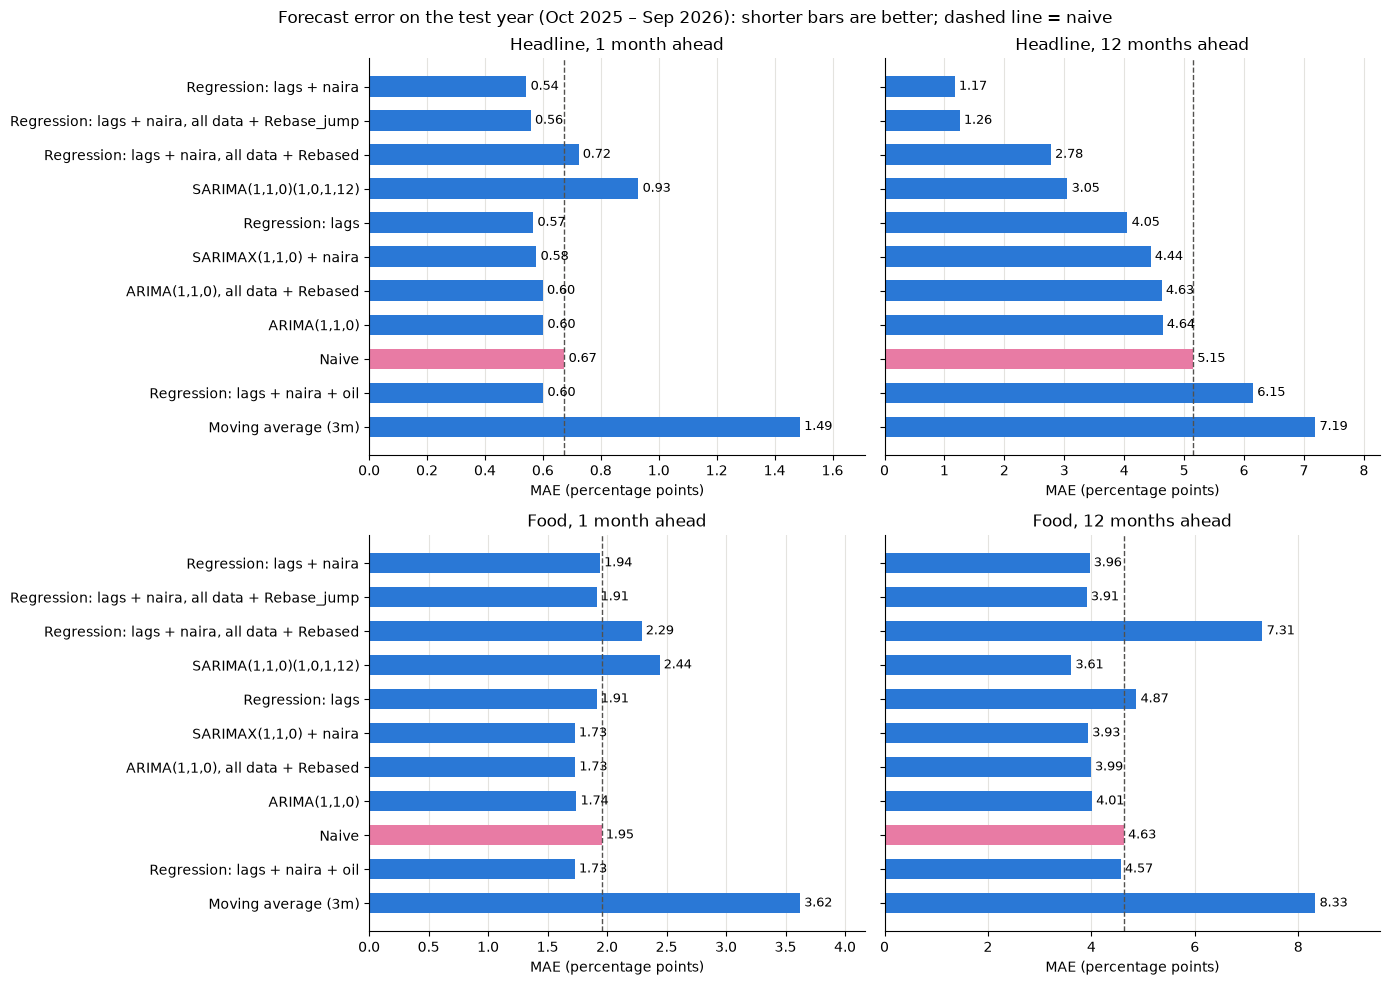

In [65]:
chart_models = [model for model in comparison.index if model != "Seasonal naive"]
tests = [("Headline", "1 month ahead"), ("Headline", "12 months ahead"),
         ("Food", "1 month ahead"), ("Food", "12 months ahead")]

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)

for ax, test_name in zip(axes.flatten(), tests):
    values = comparison.loc[chart_models, test_name]
    colours = [MODEL_COLOURS["Naive"] if model == "Naive" else HEADLINE_COLOUR for model in chart_models]
    bars = ax.barh(chart_models, values, color=colours, height=0.6)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

    ax.axvline(comparison.loc["Naive", test_name], color="#52514e", linestyle="--", linewidth=1)
    ax.set_title(f"{test_name[0]}, {test_name[1]}")
    ax.set_xlabel("MAE (percentage points)")
    ax.set_xlim(0, values.max() * 1.15)
    ax.grid(axis="x", color="#e4e3df")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

axes[0, 0].invert_yaxis()  # best 12-month headline model at the top (sharey flips all panels)
fig.suptitle("Forecast error on the test year (Oct 2025 – Sep 2026): shorter bars are better; dashed line = naive")
fig.tight_layout()

fig.savefig("images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.3 Forecast vs actual: food

We've charted headline forecasts in each phase. Here are the main models for **food**, which turned out to be harder to forecast.

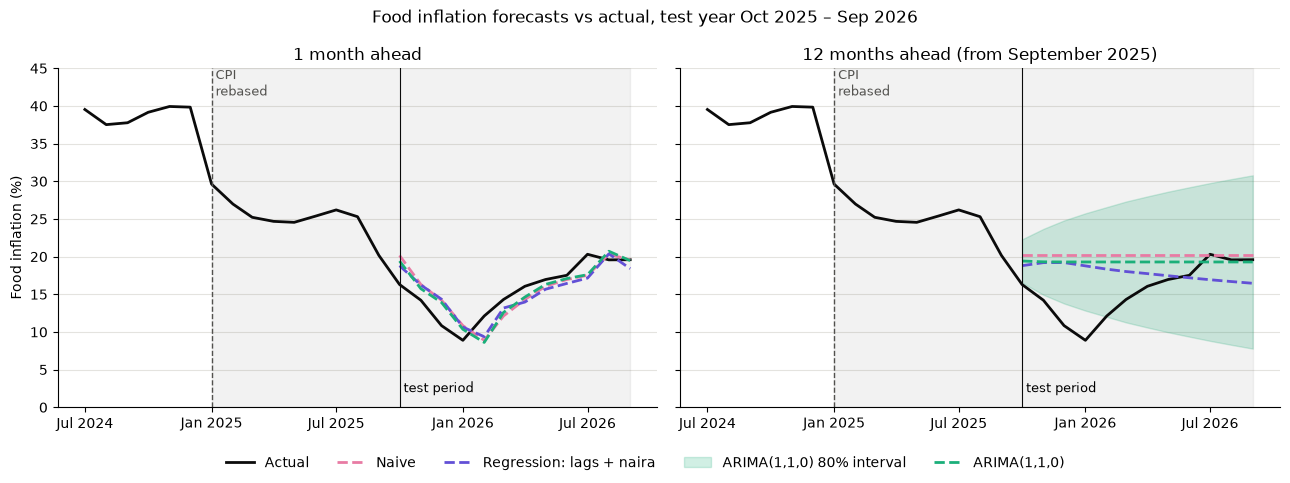

In [66]:
history = macro.loc["2024-07":, "Food"]
food_naive = {
    "1 month ahead": one_month_ahead_baselines(macro["Food"]).loc[test.index, "Naive"],
    "12 months ahead": twelve_months_ahead_baselines(train["Food"], test.index)["Naive"],
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, horizon in zip(axes, ["1 month ahead", "12 months ahead"]):
    ax.plot(history.index, history, color=ACTUAL_COLOUR, linewidth=2, label="Actual")
    ax.plot(test.index, food_naive[horizon], color=MODEL_COLOURS["Naive"], linewidth=2, linestyle="--", label="Naive")
    ax.plot(test.index, regression_forecasts[("Regression: lags + naira", "Food", horizon)],
            color=MODEL_COLOURS["Regression: lags + naira"], linewidth=2, linestyle="--", label="Regression: lags + naira")

    arima_food = arima_forecasts[("ARIMA(1,1,0)", "Food", horizon)]
    if horizon == "12 months ahead":
        arima_food, band = arima_food  # 12-month entries also hold the 80% interval
        ax.fill_between(test.index, band["lower"], band["upper"], color=MODEL_COLOURS["ARIMA(1,1,0)"], alpha=0.2,
                        label="ARIMA(1,1,0) 80% interval")
    ax.plot(test.index, arima_food, color=MODEL_COLOURS["ARIMA(1,1,0)"], linewidth=2, linestyle="--", label="ARIMA(1,1,0)")

    ax.set_ylim(0, 45)
    ax.axvline(test.index[0], color=ACTUAL_COLOUR, linewidth=0.8)
    ax.text(test.index[0], 2, " test period", fontsize=9)
    mark_rebasing(ax)
    ax.set_title(horizon if horizon == "1 month ahead" else "12 months ahead (from September 2025)")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    tidy_chart(ax)

axes[0].set_ylabel("Food inflation (%)")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False)
fig.suptitle("Food inflation forecasts vs actual, test year Oct 2025 – Sep 2026")
fig.tight_layout(rect=[0, 0.07, 1, 1])

fig.savefig("images/food_forecasts.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** **1 month ahead**, all three models follow food inflation closely, but always **one step behind**: each is mostly "last month plus a little", so they catch turning points a month late.

**12 months ahead, nobody saw the dip coming.** Food fell to 8.89% in January 2026 and then rebounded. Naive and ARIMA stayed flat at 19–20%, and the regression drifted *down* to 16.5% (the strong naira pulled it down), which was the wrong direction late in the year. Food ended the year close to where it started, so the flat forecasts looked fine by September 2026, but they were 10 points off in January. ARIMA's 80% interval caught 8 of the 12 months. The January dip fell **below** even that wide band.

### 8.4 Is one test year enough? A backtest

Our 12-month scores each come from **one single forecast**, made in September 2025. One forecast can be lucky or unlucky. For example, the
regression relied on the naira staying strong in 2026, and it did.

A **backtest** (also called a **rolling-origin evaluation**) repeats the test many times. We pretend to stand at many different past months,
called **origins**, and from each one:

1. train the model on data **up to that month only**
2. forecast the next 12 months
3. measure the MAE against what actually happened

Then we average over all origins. We use an origin every 3 months from January 2010 to December 2023, which gives **56 forecasts per model**.
Every forecast ends by December 2024, so the rebasing break never gets in the way. We compare naive, the regression with lags + naira, and
ARIMA(1,1,0).

*This cell refits each model 56 times per target, so it takes around half a minute to run.*

In [67]:
backtest_origins = pd.date_range("2010-01-01", "2023-12-01", freq="QS")  # every 3 months ("QS" = quarter start)

rows = []
for target in ["Headline", "Food"]:
    for origin in backtest_origins:
        # What actually happened in the 12 months after this origin
        actual = macro.loc[origin + pd.DateOffset(months=1): origin + pd.DateOffset(months=12), target]

        naive = macro.loc[origin, target]

        model, _, _ = fit_regression(target, ["USD_NGN_yoy"], train_end=origin)
        regression = forecast_recursive(model, target, ["USD_NGN_yoy"], last_known_date=origin)

        arima = fit_arima(target, (1, 1, 0), train_end=origin).get_forecast(steps=12).predicted_mean

        rows.append({
            "Target": target,
            "Origin": origin,
            "Naive": mae(actual, naive),
            "Regression: lags + naira": mae(actual, regression),
            "ARIMA(1,1,0)": mae(actual, arima),
        })

backtest = pd.DataFrame(rows)
backtest_models = ["Naive", "Regression: lags + naira", "ARIMA(1,1,0)"]

print("Average 12-month MAE over", len(backtest_origins), "forecasts per target:")
backtest.groupby("Target")[backtest_models].mean().round(2)

Average 12-month MAE over 56 forecasts per target:


,Naive,Regression: lags + naira,"ARIMA(1,1,0)"
Target,,,
Food,2.42,2.96,2.40
Headline,2.04,2.59,2.01


In [68]:
# How often does each model beat naive? And does it depend on the period?
for model in ["Regression: lags + naira", "ARIMA(1,1,0)"]:
    for target in ["Headline", "Food"]:
        rows_for_target = backtest[backtest["Target"] == target]
        share = (rows_for_target[model] < rows_for_target["Naive"]).mean()
        print(f"{model:25} beats naive in {share:.0%} of {target.lower()} forecasts")

# Group the origins into three periods to see whether the winner changes over time
backtest["Period"] = pd.cut(backtest["Origin"].dt.year, bins=[2009, 2014, 2019, 2023], labels=["2010-14", "2015-19", "2020-23"])
backtest.pivot_table(index="Period", columns="Target", values=backtest_models, observed=True).round(2)

Regression: lags + naira  beats naive in 43% of headline forecasts
Regression: lags + naira  beats naive in 27% of food forecasts
ARIMA(1,1,0)              beats naive in 61% of headline forecasts
ARIMA(1,1,0)              beats naive in 57% of food forecasts


ARIMA(1,1,0)          Naive          Regression: lags + naira         
Target          Food Headline  Food Headline                     Food Headline
Period                                                                        
2010-14         1.40     1.29  1.37     1.27                     1.57     1.53
2015-19         2.11     1.97  2.14     2.00                     2.58     1.75
2020-23         4.01     2.96  4.08     3.04                     5.19     4.97

**Finding:** **This changes the picture.** Over 56 forecasts from 2010 to 2023:

| Average 12-month MAE | Headline | Food |
|---|---|---|
| Naive | 2.04 | 2.42 |
| Regression: lags + naira | 2.59 | 2.96 |
| ARIMA(1,1,0) | **2.01** | **2.40** |

- **The regression is usually worse than naive, not better.** It beats naive in only **43%** of headline forecasts and **27%** of food forecasts. It did well in 2015–19 for headline (1.75 vs 2.00), but very badly in **2020–23** (4.97 vs 3.04). In those years inflation kept climbing, and the model's built-in pull back toward a long-run level kept forecasting a calm-down that didn't come.
- **ARIMA(1,1,0) is the most consistent.** It beats naive in about **60%** of forecasts, by small margins. On average it's essentially as good as naive, never much worse.
- **The regression's 1.17 in the test year was mostly a good match** between its assumptions (a steady, strong naira and easing inflation) and what happened. That's not the same as reliable skill.

Also notice the typical size of a 12-month error: about **2 points in calm periods**, and **3–5 points in turbulent ones** like 2020–23 or our test year. Any year-ahead forecast of Nigerian inflation needs a wide range around it.

### 8.5 Stress test: the June 2023 naira float

The backtest in 8.4 averages over 14 years, mostly calm ones. But forecasts matter most in a crisis. So here we zoom in on the biggest shock in
our data: the **floating of the naira in June 2023**, when the official rate jumped from about ₦461 to ₦770 per dollar in two months.

We start a 12-month forecast from **every month between July 2022 and December 2023**, which gives 18 forecasts per model:

- forecasts started **before** the float (July 2022 – May 2023) had to forecast *through* it without knowing it was coming
- forecasts started **after** the float (June – December 2023) could already see the naira's fall in the data

For each forecast, we record the MAE, and also whether the forecast was **too low in all 12 months**.

*This cell refits each model 18 times per target, so it takes a few seconds.*

In [69]:
float_origins = pd.date_range("2022-07-01", "2023-12-01", freq="MS")  # every month, from a year before the float to six months after
float_date = pd.Timestamp("2023-06-01")

rows = []
float_paths = {}  # keep each 12-month forecast path for the chart: key = (target, origin)
for target in ["Headline", "Food"]:
    for origin in float_origins:
        actual = macro.loc[origin + pd.DateOffset(months=1): origin + pd.DateOffset(months=12), target]

        model, _, _ = fit_regression(target, ["USD_NGN_yoy"], train_end=origin)
        forecasts = {
            "Naive": pd.Series(macro.loc[origin, target], index=actual.index),
            "Regression: lags + naira": forecast_recursive(model, target, ["USD_NGN_yoy"], last_known_date=origin),
            "ARIMA(1,1,0)": fit_arima(target, (1, 1, 0), train_end=origin).get_forecast(steps=12).predicted_mean,
        }
        float_paths[(target, origin)] = forecasts

        for model_name, forecast in forecasts.items():
            errors = actual - forecast  # positive error = the forecast was too low
            rows.append({
                "Target": target,
                "Origin": origin,
                "Started": "Before the float" if origin < float_date else "After the float",
                "Model": model_name,
                "MAE": errors.abs().mean(),
                "Too low all 12 months": (errors > 0).all(),
            })

float_test = pd.DataFrame(rows)

# Average 12-month MAE: all 18 starting points, then split into before / after the float
overall = float_test.pivot_table(index="Target", columns="Model", values="MAE")
overall.index = [f"{target}, all 18" for target in overall.index]
split = float_test.pivot_table(index=["Target", "Started"], columns="Model", values="MAE")
split.index = [f"{target}, started {started[0].lower() + started[1:]}" for target, started in split.index]
pd.concat([overall, split]).round(2)

Model,"ARIMA(1,1,0)",Naive,Regression: lags + naira
"Food, all 18",5.41,5.52,7.60
"Headline, all 18",4.08,4.21,7.36
"Food, started after the float",7.02,7.22,6.90
"Food, started before the float",4.39,4.45,8.05
"Headline, started after the float",5.13,5.33,6.43
"Headline, started before the float",3.42,3.49,7.96


In [70]:
# Which model had the lowest MAE for each starting point?
best_rows = float_test.loc[float_test.groupby(["Target", "Origin"])["MAE"].idxmin()]
print("Number of starting points where each model was best:")
print(best_rows.groupby(["Target", "Model"]).size().to_string())

# How often was each model's forecast below the actual value in every one of the 12 months?
print("\nShare of forecasts that were too low in all 12 months:")
print(float_test.groupby("Model")["Too low all 12 months"].mean().map("{:.0%}".format).to_string())

Number of starting points where each model was best:
Target    Model                   
Food      ARIMA(1,1,0)                13
          Naive                        1
          Regression: lags + naira     4
Headline  ARIMA(1,1,0)                16
          Naive                        1
          Regression: lags + naira     1

Share of forecasts that were too low in all 12 months:
Model
ARIMA(1,1,0)                 89%
Naive                        94%
Regression: lags + naira    100%


The chart shows what that looks like. Black is actual headline inflation. Each dashed line is one 12-month forecast, started from the dot at its left
end (one every 3 months, to keep the chart readable).

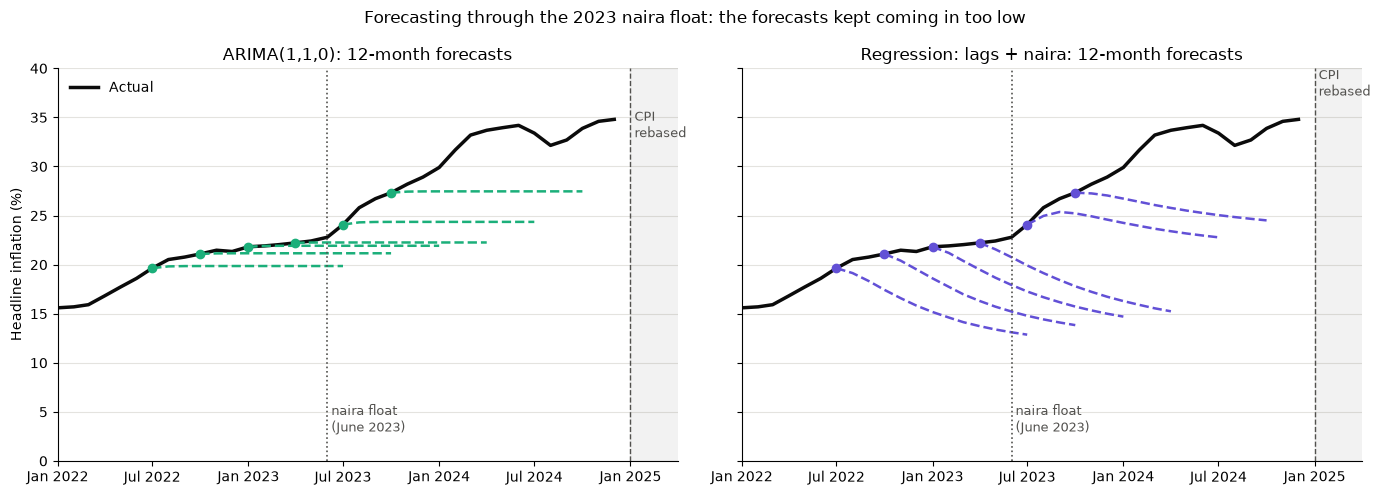

In [71]:
chart_origins = pd.date_range("2022-07-01", "2023-10-01", freq="QS")  # every 3rd starting point
actual_headline = macro.loc["2022-01":"2024-12", "Headline"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, model_name in zip(axes, ["ARIMA(1,1,0)", "Regression: lags + naira"]):
    ax.plot(actual_headline.index, actual_headline, color=ACTUAL_COLOUR, linewidth=2.5, label="Actual")
    for origin in chart_origins:
        path = float_paths[("Headline", origin)][model_name]
        # Start each line at the actual value on its starting month, so it's clear where the forecast began
        ax.plot([origin] + list(path.index), [macro.loc[origin, "Headline"]] + list(path),
                color=MODEL_COLOURS[model_name], linewidth=1.8, linestyle="--")
        ax.plot(origin, macro.loc[origin, "Headline"], "o", color=MODEL_COLOURS[model_name], markersize=6)

    ax.axvline(float_date, color="#52514e", linestyle=":", linewidth=1.2)
    ax.text(float_date, 3, " naira float\n (June 2023)", fontsize=9, color="#52514e")
    mark_rebasing(ax)
    ax.set_xlim(pd.Timestamp("2022-01-01"), pd.Timestamp("2025-04-01"))
    ax.set_ylim(0, 40)
    ax.set_title(f"{model_name}: 12-month forecasts")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    tidy_chart(ax)

axes[0].set_ylabel("Headline inflation (%)")
axes[0].legend(loc="upper left", frameon=False)
fig.suptitle("Forecasting through the 2023 naira float: the forecasts kept coming in too low")
fig.tight_layout()

fig.savefig("images/float_stress_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** **ARIMA(1,1,0) held up best through the float, but "best" here means "failed least".**

| Average 12-month MAE | ARIMA(1,1,0) | Naive | Regression: lags + naira |
|---|---|---|---|
| Headline, all 18 starting points | **4.08** | 4.21 | 7.36 |
| Headline, started before the float | **3.42** | 3.49 | 7.96 |
| Headline, started after the float | **5.13** | 5.33 | 6.43 |
| Food, all 18 starting points | **5.41** | 5.52 | 7.60 |

- **ARIMA had the lowest error for 16 of the 18 headline forecasts** (13 of 18 for food). But its lead over naive is only about 0.1 points. It held up best mainly because it changes the forecast least.
- **Almost every forecast was too low.** Most forecasts were below the actual figure in **every one of their 12 months**: 89% of ARIMA's, 94% of naive's and 100% of the regression's. Errors of 4–8 points are about double the typical error in calm years (8.4). No model saw the float coming. That's not a flaw we could have fixed: the float was a **policy decision**, and nothing in the past data announces it in advance.
- **The naira-based regression did worst, which looks backwards at first.** Before June 2023, the official rate was nearly fixed, so the naira input sent almost no warning. Meanwhile, the model's pull toward a long-run average made it forecast **falling** inflation (the downward lines in the right-hand chart). From April 2023 it forecast 15% for a year later, and the actual figure was 33.7%. Once the float showed up in the exchange rate, it partly caught up. For food forecasts started after the float, it was narrowly the best model (6.90 vs ARIMA's 7.02).

**Lesson:** the naira drives inflation, but a model can only react to a devaluation **after** it happens. Through a policy shock, the most honest forecast is "probably higher than this, with a wide range". That's why the final forecast in Phase 9 relies on its range more than its single number.

### 8.6 Verdict

**Answer to key question 5: simple is very hard to beat.**

- **1 month ahead:** the regression with lags + naira was best on the test year (0.54 vs naive 0.67). Most models beat naive here, but the gains are small, because inflation rarely moves much in one month.
- **12 months ahead:** across 14 years of backtests, **no model reliably beats naive**. ARIMA(1,1,0) matches it or does slightly better, and it's the most consistent. The regression with the naira can be excellent when the naira's trend keeps going, as in our test year, but it's often worse than naive when the trend changes.
- **The naira is a real driver** (Phases 4 and 6), but using it to forecast a year ahead means guessing where the naira itself is going. That's the hard part.

**What this means for the final forecast (Phase 9):** the most defensible main forecast is **ARIMA(1,1,0), fitted on all data with the `Rebased` dummy**, because:
1. It held up best across 14 years of backtests.
2. It comes with an 80% interval.
3. It uses every month up to September 2026, including the new CPI.

We can show the regression's naira-based path alongside it as a **scenario** ("if the naira's recent trend continues") rather than as the main forecast.

## 9. Final forecast: October 2026 to September 2027

**Question:** Where are headline and food inflation heading over the next 6–12 months, and how sure can we be?

From Phase 8, our plan is:

- **Main forecast: ARIMA(1,1,0) with the `Rebased` dummy**, now fitted on **all 285 months** (January 2003 – September 2026). It held up best in
  the 14-year backtest, and it gives an **80% interval**.
- **Scenario: Regression with lags + naira** (with the `Rebase_jump` dummy, also on all data). It answers "what if the naira's recent strength
  continues?" It's a scenario, not the main forecast, because the backtest showed it's often wrong when the naira's trend changes.

There's no test set any more. We use every month we have, because these forecasts are for months that haven't happened yet.

### 9.1 Fit on all data and forecast 12 months

`get_forecast()` needs the future values of the `Rebased` dummy. That's easy, because we know the rebased CPI stays in use: `Rebased` = 1 for
every future month.

In [72]:
last_month = macro.index[-1]
future_dates = pd.date_range(last_month + pd.DateOffset(months=1), periods=12, freq="MS")
print(f"Last known month: {last_month:%B %Y}. Forecasting {future_dates[0]:%B %Y} to {future_dates[-1]:%B %Y}.")

final_forecasts = {}
for target in ["Headline", "Food"]:
    # Main forecast: ARIMA(1,1,0) + Rebased, fitted on every month we have
    result = fit_arima(target, (1, 1, 0), exog_columns=["Rebased"], train_end=last_month)
    forecast = result.get_forecast(steps=12, exog=pd.DataFrame({"Rebased": 1}, index=future_dates))
    interval = forecast.conf_int(alpha=0.2)  # 80% interval
    interval.columns = ["lower", "upper"]

    # Scenario: regression with lags + naira, naira's year-on-year change held at its latest value
    model, _, _ = fit_regression(target, ["USD_NGN_yoy"], ["Rebase_jump"], train_end=last_month)
    scenario = forecast_recursive(model, target, ["USD_NGN_yoy"], ["Rebase_jump"], last_known_date=last_month)

    final_forecasts[target] = pd.DataFrame({
        "Forecast": forecast.predicted_mean,
        "Low (80%)": interval["lower"],
        "High (80%)": interval["upper"],
        "Naira scenario": scenario,
    })
    print(f"{target}: ARIMA coefficients {result.params.round(2).to_dict()}")

print(f"\nNaira's latest year-on-year change (held constant in the scenario): {macro.loc[last_month, 'USD_NGN_yoy']:.1f}%")

Last known month: September 2026. Forecasting October 2026 to September 2027.
Headline: ARIMA coefficients {'Rebased': -6.96, 'ar.L1': 0.21, 'sigma2': 2.09}
Food: ARIMA coefficients {'Rebased': -9.74, 'ar.L1': 0.18, 'sigma2': 4.97}

Naira's latest year-on-year change (held constant in the scenario): -11.4%


In [73]:
print("Headline inflation forecast (%)")
final_forecasts["Headline"].round(1)

Headline inflation forecast (%)


,Forecast,Low (80%),High (80%),Naira scenario
2026-10-01,14.5,12.6,16.3,14.2
2026-11-01,14.4,11.5,17.3,13.8
2026-12-01,14.4,10.7,18.2,13.6
2027-01-01,14.4,10.0,18.8,13.3
2027-02-01,14.4,9.4,19.4,13.0
2027-03-01,14.4,8.9,19.9,12.8
2027-04-01,14.4,8.4,20.4,12.6
2027-05-01,14.4,8.0,20.9,12.4
2027-06-01,14.4,7.6,21.3,12.2
2027-07-01,14.4,7.2,21.7,12.1


In [74]:
print("Food inflation forecast (%)")
final_forecasts["Food"].round(1)

Food inflation forecast (%)


,Forecast,Low (80%),High (80%),Naira scenario
2026-10-01,19.6,16.7,22.4,19.2
2026-11-01,19.6,15.2,24.0,18.7
2026-12-01,19.6,14.0,25.2,18.1
2027-01-01,19.6,13.0,26.2,17.7
2027-02-01,19.6,12.2,27.0,17.3
2027-03-01,19.6,11.4,27.8,16.9
2027-04-01,19.6,10.7,28.5,16.6
2027-05-01,19.6,10.0,29.1,16.2
2027-06-01,19.6,9.4,29.8,15.9
2027-07-01,19.6,8.9,30.3,15.6


### 9.2 Summary: 6 and 12 months ahead

In [75]:
rows = []
for target in ["Headline", "Food"]:
    for months_ahead in [6, 12]:
        row = final_forecasts[target].iloc[months_ahead - 1]
        rows.append({
            "Target": target,
            "Month": f"{final_forecasts[target].index[months_ahead - 1]:%b %Y}",
            "Forecast (%)": row["Forecast"],
            "80% range (%)": f"{row['Low (80%)']:.1f} to {row['High (80%)']:.1f}",
            "Naira scenario (%)": row["Naira scenario"],
        })
forecast_summary = pd.DataFrame(rows)
forecast_summary.round(1)

,Target,Month,Forecast (%),80% range (%),Naira scenario (%)
0,Headline,Mar 2027,14.4,8.9 to 19.9,12.8
1,Headline,Sep 2027,14.4,6.5 to 22.4,11.8
2,Food,Mar 2027,19.6,11.4 to 27.8,16.9
3,Food,Sep 2027,19.6,7.8 to 31.4,15.1


### 9.3 The forecast chart

The solid line is history; the dashed line and shaded band are the main forecast and its 80% range; the violet dotted line is the naira scenario.

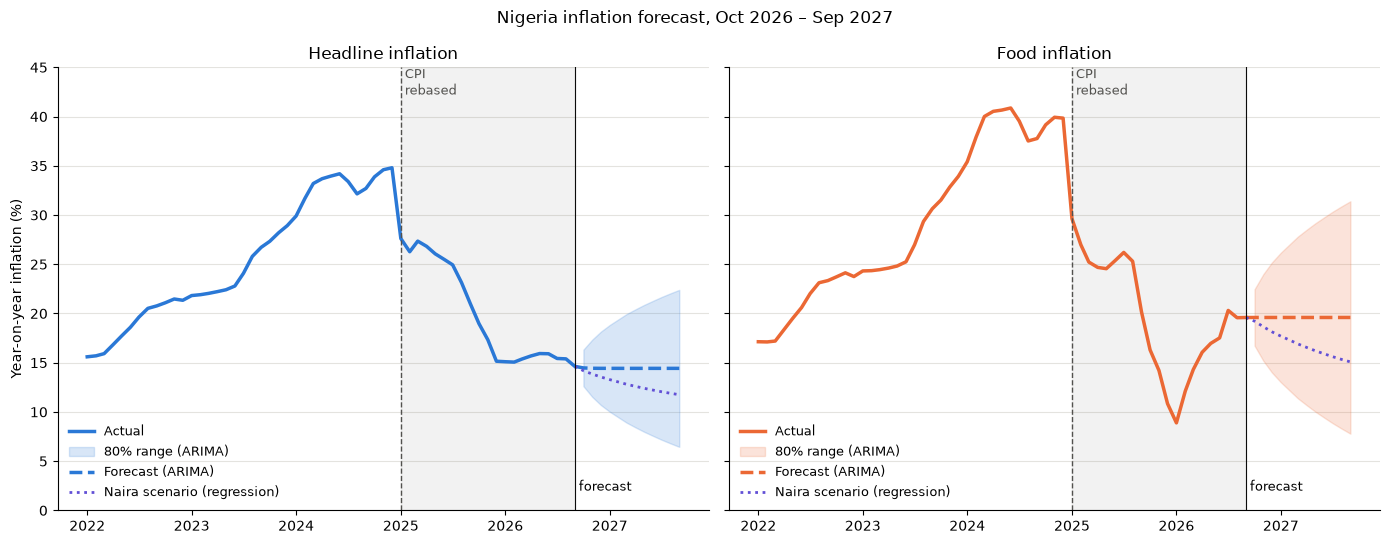

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

for ax, target, colour in zip(axes, ["Headline", "Food"], [HEADLINE_COLOUR, FOOD_COLOUR]):
    history = macro.loc["2022-01":, target]
    forecast = final_forecasts[target]

    # Join the forecast to the last actual month so the lines connect
    joined_dates = [last_month] + list(forecast.index)
    joined_forecast = [history.iloc[-1]] + list(forecast["Forecast"])
    joined_scenario = [history.iloc[-1]] + list(forecast["Naira scenario"])

    ax.plot(history.index, history, color=colour, linewidth=2.5, label="Actual")
    ax.fill_between(forecast.index, forecast["Low (80%)"], forecast["High (80%)"], color=colour, alpha=0.18,
                    label="80% range (ARIMA)")
    ax.plot(joined_dates, joined_forecast, color=colour, linewidth=2.5, linestyle="--", label="Forecast (ARIMA)")
    ax.plot(joined_dates, joined_scenario, color=FX_COLOUR, linewidth=2, linestyle=":", label="Naira scenario (regression)")

    ax.set_ylim(0, 45)
    ax.axvline(last_month, color=ACTUAL_COLOUR, linewidth=0.8)
    ax.text(last_month, 2, " forecast", fontsize=9)
    mark_rebasing(ax)
    ax.set_title(f"{target} inflation")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    tidy_chart(ax)
    ax.legend(loc="lower left", frameon=False, fontsize=9)

axes[0].set_ylabel("Year-on-year inflation (%)")
fig.suptitle(f"Nigeria inflation forecast, {future_dates[0]:%b %Y} – {future_dates[-1]:%b %Y}")
fig.tight_layout()

fig.savefig("images/final_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** | | Mar 2027 (6 months) | Sep 2027 (12 months) |
|---|---|---|
| **Headline forecast** | **14.4%** (80% range 8.9–19.9) | **14.4%** (80% range 6.5–22.4) |
| Headline, naira scenario | 12.8% | 11.8% |
| **Food forecast** | **19.6%** (80% range 11.4–27.8) | **19.6%** (80% range 7.8–31.4) |
| Food, naira scenario | 16.9% | 15.1% |

**Answer to the project question: will the decline continue, level off, or reverse?** Our best single estimate is that headline inflation **levels off at about 14–15%**, close to where it is now. It **keeps falling** (to about 12% by September 2027) **only if the naira stays about 11% stronger** than a year earlier, which is the naira scenario. A **reversal** is well within the range: the top of the 80% range reaches about 20% by March 2027 and 22% by September 2027.

**Food is the bigger worry.** It's already about 5 points above headline and has risen every few months since January 2026 (from 8.9% to 19.6%). The main forecast holds it at about 19.6%, and its range is wide in both directions.

**How to read the flat line.** A flat ARIMA forecast doesn't mean "inflation won't change". It means **"we have no reliable signal about which way it will move"**. Phase 8 showed that no model we built could reliably forecast the direction a year ahead. That's why the **range matters more than the line**. It may even be too narrow: in the test year, only 8 of 12 months landed inside ARIMA's 80% range, fewer than the 9–10 we'd expect.

### 9.4 What could break this forecast?

A forecast built from past patterns assumes the future behaves like the past. These are the events most likely to break that assumption, roughly in order of how much we think they matter:

1. **Exchange-rate (FX) policy.** The naira is the strongest driver we found: its fall led every inflation wave since 2016, usually within 1–3 months. Right now it's about **11% stronger** than a year ago, which helps. A policy change, a drop in foreign-currency inflows, or pressure on reserves that weakens the naira again would push inflation **up** within months.
2. **Fuel prices.** Petrol has not been subsidised since mid-2023, so world oil prices now reach Nigerian pump prices, and through them transport and food costs. In September 2026, Bonny Light crude averaged about **\$117 a barrel, 67% higher** than a year earlier. Our models found little link between oil and inflation, but most of that history comes from the **subsidy era**, so the past may *understate* this risk now.
3. **Harvest and food supply.** Food inflation has been climbing since January 2026. The lean season before the main harvest (roughly May–August), insecurity in farming areas, flooding and fertiliser costs could push it higher. A good harvest at the end of 2026 would help.
4. **CBN interest-rate decisions.** If the CBN's Monetary Policy Committee cuts rates as inflation falls, cheaper borrowing can boost spending and weaken the naira, which pushes inflation up. Holding rates high supports the naira. **Our models don't include interest rates at all.**
5. **Elections.** Nigeria's general elections are due in early 2027, inside our forecast window. Extra spending around elections can add to price pressures.
6. **Data revisions.** NBS revised its 2025 figures by about 3 points in January 2026 (Phase 3). Another revision or methodology change could move the published numbers without any change in actual prices. And our data comes from an **unofficial** CBN feed that could change or disappear.

**Bottom line:** expect headline inflation **around 14–15%** over the next year, with a **realistic range of about 7–22%**. The naira and fuel prices are the two things to watch: they're the most likely reasons for the forecast to be wrong.